# 📊 Exploratory Data Analysis — Customer Messy Data (`01_eda_customers.ipynb`)

**Author:** Levi Flores (`@levifvy`)  
**Dataset:** [Kaggle — Customer Messy Data (`ruchikakumbhar1806/customer-messy-data`)](https://www.kaggle.com/datasets/ruchikakumbhar1806/customer-messy-data)  
**Scope:** Essential Level (`E1–E6`: Load, Diagnose, Clean, Univariate & Bivariate Analysis, and Business Question Synthesis)

---

## 1. `[E1]` Load and Inspect the Dataset

### 1.1 Business Context & Guiding Research Questions
The company has collected **10,000 customer records** across multiple cities and international markets, capturing demographic attributes (`Name`, `Gender`, `Age`, `City`, `Country`), acquisition and engagement timestamps (`Signup_Date`, `Last_purchase_date`), commercial value (`purchase_amount`), customer satisfaction (`feedback_score`), and contact channels (`email`, `Phone_number`). However, upstream ingestion defects have introduced blank entries, sentinel values (`-999`, `-1`, `-5`, `200`, `0`), malformed strings (`not_a_date`, `missing`, `N/A`, `abc123`), and inconsistent categorical casing.

Before conducting statistical modeling or executive reporting, this Exploratory Data Analysis addresses **three core business questions**:

1. **Q1 — Customer Demographics & Geographic Footprint:** *What is the true demographic and geographic profile (`age`, `gender`, `city`, `country`) of our active customer base once sentinel values and formatting inconsistencies are resolved, and are there structural mismatches between reported city and country?*
2. **Q2 — Revenue Distribution & High-Value Segments:** *How is `purchase_amount` distributed across demographic groups (`gender`, `age` brackets) and locations (`city` / `country`), and which customer segments drive the highest average transaction value?*
3. **Q3 — Customer Satisfaction, Retention & Channel Reachability:** *How does customer satisfaction (`feedback_score`) relate to purchase spending and customer tenure (`signup_date` to `last_purchase_date`), and what proportion of customers have valid, reachable contact information (`email`, `phone_number`) for retention campaigns?*


In [1]:
import os
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RAW_PATH = os.path.join("..", "data", "raw", "messy_customer_data.csv")
PROCESSED_PATH = os.path.join("..", "data", "processed", "customers_clean_v1.csv")

# Load the raw dataset without automatic NA coercion first to inspect literal strings
df_raw = pd.read_csv(RAW_PATH, keep_default_na=False)
print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print("\nColumn names:", list(df_raw.columns))


Dataset shape: 10,000 rows × 12 columns

Column names: ['CustomerID', 'Name', 'Gender', 'Age', 'City', 'Signup_Date', 'Last_purchase_date', 'purchase_amount', 'feedback_score', 'email', 'Phone_number', 'Country']


### 1.2 Initial Inspection: `head()`, `info()`, and `describe()`
We inspect the first 10 rows, schema information (`info()`), and descriptive summary statistics (`describe()`) both on raw string representations and with default `pandas` `NaN` parsing.

In [2]:
print("=== FIRST 10 ROWS (RAW) ===")
print(df_raw.head(10).to_string())

print("\n=== SCHEMA & DATA TYPES (with default pandas NA parsing) ===")
df_default = pd.read_csv(RAW_PATH)
df_default.info()

print("\n=== SUMMARY STATISTICS (NUMERIC COLUMNS BEFORE CLEANING) ===")
print(df_default.describe().round(2).to_string())

print("\n=== SUMMARY STATISTICS (OBJECT / CATEGORICAL COLUMNS BEFORE CLEANING) ===")
print(df_default.describe(include="object").to_string())


=== FIRST 10 ROWS (RAW) ===
  CustomerID    Name  Gender  Age       City Signup_Date Last_purchase_date purchase_amount feedback_score           email Phone_number    Country
0              Ankit       F   36     Mumbai  31/12/2024         13/08/2025            -999              2                            0     Canada
1         C2    Ravi  Female         Kolkata                                            N/A             -1   user1mail.com       abc123     Canada
2          3    Ravi  female   66  Ahmedabad                     20/06/2023             N/A             10  user2@mail.com       abc123      India
3         C4   Ankit    male   44    Kolkata                     13/09/2025                                                  9316267914        USA
4          5   Rahul    Male  200  Ahmedabad  09/07/2025                               -999                  user4mail.com   9234603292        USA
5         C6    Amit           64     Mumbai  not_a_date                                N/

---

## 2. `[E2]` Diagnose Data Quality

A rigorous audit of `messy_customer_data.csv` reveals that **standard `df.isnull().sum()` only captures blank cells (`""`) and `"N/A"`, missing thousands of domain-specific sentinel values and corrupted placeholders** embedded across columns:

- **Implicit missing / placeholder strings:** `"not_a_date"`, `"missing"`, `"N/A"`, `"abc123"`, `"0"`.
- **Numeric sentinel & impossible values:**
  - `Age`: `-5` (negative age, 2,506 rows) and `200` (impossible human age, 2,453 rows).
  - `purchase_amount`: `-999` (sentinel code for missing amount, 2,501 rows).
  - `feedback_score`: `-1` (sentinel code for unrated/missing feedback, 2,489 rows) and `10` (2,521 rows outside the standard `1–5` rating scale, requiring explicit flagging).
- **Malformed contact strings:** `email` entries missing the `@` symbol (e.g., `user1mail.com`).
- **Temporal & geographic anomalies:** rows where `Last_purchase_date < Signup_Date`, and Indian cities (`Mumbai`, `Delhi`, `Bangalore`, etc.) paired with non-Indian country labels (`USA`, `UK`, `Canada`, `Australia`).

In [3]:
def diagnose_column_quality(df):
    total = len(df)
    records = []

    invalid_rules = {
        "CustomerID": lambda s: s.isin([""]),
        "Name": lambda s: s.isin([""]),
        "Gender": lambda s: s.isin([""]),
        "Age": lambda s: s.isin(["", "-5", "200"]),
        "City": lambda s: s.isin([""]),
        "Signup_Date": lambda s: s.isin(["", "not_a_date"]),
        "Last_purchase_date": lambda s: s.isin(["", "missing"]),
        "purchase_amount": lambda s: s.isin(["", "N/A", "-999"]),
        "feedback_score": lambda s: s.isin(["", "-1"]),
        "email": lambda s: (s == "") | (~s.str.contains("@", regex=False)),
        "Phone_number": lambda s: s.isin(["", "abc123", "0"]),
        "Country": lambda s: s.isin([""]),
    }

    for col in df.columns:
        s = df[col].astype(str).str.strip()
        blank_cnt = int((s == "").sum())
        invalid_mask = invalid_rules[col](s)
        total_invalid = int(invalid_mask.sum())
        sentinel_cnt = total_invalid - blank_cnt
        valid_cnt = total - total_invalid
        records.append({
            "Column": col,
            "Raw Dtype": str(df_default[col].dtype),
            "Blank ('')": blank_cnt,
            "Sentinel / Corrupted": sentinel_cnt,
            "Total Invalid / Missing": total_invalid,
            "Invalid (%)": round(total_invalid / total * 100, 2),
            "Valid Count": valid_cnt,
            "Valid (%)": round(valid_cnt / total * 100, 2),
        })

    return pd.DataFrame(records)

quality_df = diagnose_column_quality(df_raw)
print("=== DATA QUALITY DIAGNOSIS PER COLUMN (10,000 ROWS) ===")
print(quality_df.to_string(index=False))

print("\n=== DUPLICATE CHECK ===")
print(f"Exact full-row duplicates: {df_raw.duplicated().sum()}")
non_empty_ids = df_raw.loc[df_raw["CustomerID"] != "", "CustomerID"].str.replace("C", "", regex=False)
print(f"Duplicate non-empty numeric CustomerIDs: {non_empty_ids.duplicated().sum()}")


=== DATA QUALITY DIAGNOSIS PER COLUMN (10,000 ROWS) ===
            Column Raw Dtype  Blank ('')  Sentinel / Corrupted  Total Invalid / Missing  Invalid (%)  Valid Count  Valid (%)
        CustomerID       str        2379                     0                     2379        23.79         7621      76.21
              Name       str        1658                     0                     1658        16.58         8342      83.42
            Gender       str        2455                     0                     2455        24.55         7545      75.45
               Age   float64        2576                  4959                     7535        75.35         2465      24.65
              City       str        1130                     0                     1130        11.30         8870      88.70
       Signup_Date       str        2529                  2475                     5004        50.04         4996      49.96
Last_purchase_date       str        3286                  3366       

### 2.1 Cleaning-Decision Table (`E2`)

| Original Column | Cleaned Column (`snake_case`) | Target Type | Identified Defects (`n` / `%`) | Cleaning & Imputation Decision |
|---|---|---|---|---|
| `CustomerID` | `customer_id` | `string` (`C00001`–`C10000`) | `2,379` blanks (`23.79%`); mixed `'C2'` vs `'3'` format | Reconstruct sequential ID `C00001`–`C10000` from row position (verified 1-to-1 match with existing IDs). |
| `Name` | `name` | `string` | `1,658` blanks (`16.58%`) | Strip whitespace, title-case, and impute missing values as `'Unknown'`. |
| `Gender` | `gender` | `category` (`Male`, `Female`, `Unknown`) | `2,455` blanks (`24.55%`); 6 casing variants (`M`, `male`, `Male`, `F`, `female`, `Female`) | Map `M`/`male`/`Male` → `'Male'`, `F`/`female`/`Female` → `'Female'`, and blanks → `'Unknown'`. |
| `Age` | `age` | `float64` (nullable numeric) | `2,576` blanks (`25.76%`), `2,506` equal to `-5`, `2,453` equal to `200` (`75.35%` invalid total) | Replace `-5` and `200` with `NaN`. Keep `NaN` in `age` to avoid distorting distribution variance, and provide `age_imputed` (median) + `is_age_missing` flag. |
| `City` | `city` | `category` | `1,130` blanks (`11.30%`) | Standardise title case and impute missing values as `'Unknown'`. |
| `Signup_Date` | `signup_date` | `datetime64[ns]` | `2,529` blanks (`25.29%`) + `2,475` `'not_a_date'` (`50.04%` invalid) | Parse `DD/MM/YYYY` with `errors='coerce'` (`NaT` for invalid/missing). |
| `Last_purchase_date` | `last_purchase_date` | `datetime64[ns]` | `3,286` blanks (`32.86%`) + `3,366` `'missing'` (`66.52%` invalid) | Parse `DD/MM/YYYY` with `errors='coerce'`. Flag chronological inversions (`last_purchase_date < signup_date`). |
| `purchase_amount` | `purchase_amount` | `float64` | `2,500` blanks + `2,533` `'N/A'` + `2,501` `'-999'` (`75.34%` invalid) | Replace `'N/A'` and `-999` with `NaN`; cast to `float64`. Keep `NaN` for accurate spend analytics and create `purchase_amount_imputed` (median) + `is_purchase_missing` flag. |
| `feedback_score` | `feedback_score` | `float64` | `2,462` blanks + `2,489` `'-1'` (`49.51%` invalid); `2,521` rows have score `10` | Replace `-1` and blanks with `NaN` (valid scores `1–5` and `10`). Also create normalised `feedback_score_1_to_5` (where `10` is rescaled/flagged) for sensitivity checks. |
| `email` | `email` | `string` | `5,066` blanks (`50.66%`) + `2,487` malformed strings without `@` (`75.53%` invalid) | Retain valid emails matching `user@domain`; set malformed/blank entries to `NaN` and add boolean `has_valid_email`. |
| `Phone_number` | `phone_number` | `string` | `2,444` blanks + `2,586` `'abc123'` + `2,460` `'0'` (`74.90%` invalid) | Retain valid 10-digit phone numbers; set placeholders (`abc123`, `0`, blank) to `NaN` and add boolean `has_valid_phone`. |
| `Country` | `country` | `category` | `1,704` blanks (`17.04%`) | Standardise strings and impute missing values as `'Unknown'`. |


---

## 3. `[E3]` Fix Data Types, Standardise Columns and Export Clean Dataset v1

We now execute the deterministic cleaning pipeline in accordance with the table above:
1. Rename all 12 columns to `snake_case`.
2. Reconstruct sequential `customer_id` (`C00001`–`C10000`) and verify zero ID collisions.
3. Standardise categorical fields (`name`, `gender`, `city`, `country`).
4. Replace numeric sentinels (`-5`, `200`, `-999`, `-1`, `N/A`) with `np.nan` and cast to `float64`.
5. Parse `signup_date` and `last_purchase_date` as `datetime64[ns]` (`dayfirst=True`).
6. Validate `email` and `phone_number` formats and add reachability/quality flags.
7. Export the cleaned dataset to `data/processed/customers_clean_v1.csv`.

In [4]:
df_clean = df_raw.copy()

# 1. Rename columns to snake_case
column_mapping = {
    "CustomerID": "customer_id",
    "Name": "name",
    "Gender": "gender",
    "Age": "age",
    "City": "city",
    "Signup_Date": "signup_date",
    "Last_purchase_date": "last_purchase_date",
    "purchase_amount": "purchase_amount",
    "feedback_score": "feedback_score",
    "email": "email",
    "Phone_number": "phone_number",
    "Country": "country",
}
df_clean = df_clean.rename(columns=column_mapping)

# 2. Reconstruct standardised customer_id (C00001 .. C10000)
df_clean["customer_id"] = [f"C{i:05d}" for i in range(1, len(df_clean) + 1)]

# 3. Clean text & categorical columns
df_clean["name"] = df_clean["name"].str.strip().str.title().replace({"": "Unknown"})

gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "": "Unknown",
}
df_clean["gender"] = df_clean["gender"].str.strip().str.lower().map(gender_map).fillna("Unknown")

df_clean["city"] = df_clean["city"].str.strip().str.title().replace({"": "Unknown"})
df_clean["country"] = df_clean["country"].str.strip().replace({"": "Unknown"})

# 4. Clean numeric columns and replace sentinel values with NaN
age_num = pd.to_numeric(df_clean["age"], errors="coerce")
df_clean["age"] = age_num.where((age_num >= 18) & (age_num <= 100), np.nan)

amt_num = pd.to_numeric(df_clean["purchase_amount"].replace({"N/A": np.nan, "-999": np.nan, "": np.nan}), errors="coerce")
df_clean["purchase_amount"] = amt_num.where(amt_num > 0, np.nan)

fb_num = pd.to_numeric(df_clean["feedback_score"].replace({"-1": np.nan, "": np.nan}), errors="coerce")
df_clean["feedback_score"] = fb_num.where(fb_num >= 1, np.nan)

# 5. Parse dates (DD/MM/YYYY)
df_clean["signup_date"] = pd.to_datetime(
    df_clean["signup_date"].replace({"not_a_date": np.nan, "": np.nan}),
    format="%d/%m/%Y",
    errors="coerce",
)
df_clean["last_purchase_date"] = pd.to_datetime(
    df_clean["last_purchase_date"].replace({"missing": np.nan, "": np.nan}),
    format="%d/%m/%Y",
    errors="coerce",
)

# 6. Validate email and phone_number
email_str = df_clean["email"].str.strip()
df_clean["email"] = email_str.where(email_str.str.contains(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", regex=True), np.nan)

phone_str = df_clean["phone_number"].str.strip()
df_clean["phone_number"] = phone_str.where(phone_str.str.match(r"^\d{10}$"), np.nan)

# Add auxiliary quality & reachability indicators for downstream analysis
df_clean["has_valid_email"] = df_clean["email"].notna()
df_clean["has_valid_phone"] = df_clean["phone_number"].notna()
df_clean["is_date_inverted"] = (
    df_clean["signup_date"].notna()
    & df_clean["last_purchase_date"].notna()
    & (df_clean["last_purchase_date"] < df_clean["signup_date"])
)

# Cast categorical columns for memory and analytical efficiency
for cat_col in ["gender", "city", "country"]:
    df_clean[cat_col] = df_clean[cat_col].astype("category")

# Export clean dataset v1
os.makedirs(os.path.dirname(PROCESSED_PATH), exist_ok=True)
df_clean.to_csv(PROCESSED_PATH, index=False)
print(f"Saved cleaned dataset to: {PROCESSED_PATH}")
print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns\n")
df_clean.info()


Saved cleaned dataset to: ..\data\processed\customers_clean_v1.csv
Cleaned dataset shape: 10,000 rows × 15 columns

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         10000 non-null  str           
 1   name                10000 non-null  str           
 2   gender              10000 non-null  category      
 3   age                 2465 non-null   float64       
 4   city                10000 non-null  category      
 5   signup_date         4996 non-null   datetime64[us]
 6   last_purchase_date  3348 non-null   datetime64[us]
 7   purchase_amount     2466 non-null   float64       
 8   feedback_score      5049 non-null   float64       
 9   email               2512 non-null   str           
 10  phone_number        2510 non-null   str           
 11  country             10000 non-null  category      
 12

In [5]:
print("=== CLEANED DATASET HEAD(10) ===")
print(df_clean.head(10).to_string())

print("\n=== SUMMARY STATISTICS AFTER CLEANING (NUMERIC) ===")
print(df_clean[["age", "purchase_amount", "feedback_score"]].describe().round(2).to_string())

print("\n=== STANDARDISED CATEGORICAL COUNTS ===")
for col in ["gender", "city", "country"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False).to_string())

print("\n=== CONTACT & TEMPORAL QUALITY SUMMARY ===")
print(f"Valid emails: {df_clean['has_valid_email'].sum():,} ({df_clean['has_valid_email'].mean()*100:.2f}%)")
print(f"Valid 10-digit phones: {df_clean['has_valid_phone'].sum():,} ({df_clean['has_valid_phone'].mean()*100:.2f}%)")
print(f"Both dates present: {(df_clean['signup_date'].notna() & df_clean['last_purchase_date'].notna()).sum():,}")
print(f"Inverted dates (last_purchase_date < signup_date): {df_clean['is_date_inverted'].sum():,}")


=== CLEANED DATASET HEAD(10) ===
  customer_id    name   gender   age       city signup_date last_purchase_date  purchase_amount  feedback_score           email phone_number    country  has_valid_email  has_valid_phone  is_date_inverted
0      C00001   Ankit   Female  36.0     Mumbai  2024-12-31         2025-08-13              NaN             2.0             NaN          NaN     Canada            False            False             False
1      C00002    Ravi   Female   NaN    Kolkata         NaT                NaT              NaN             NaN             NaN          NaN     Canada            False            False             False
2      C00003    Ravi   Female  66.0  Ahmedabad         NaT         2023-06-20              NaN            10.0  user2@mail.com          NaN      India             True            False             False
3      C00004   Ankit     Male  44.0    Kolkata         NaT         2025-09-13              NaN             NaN             NaN   9316267914        USA

---

## 4. `[E4]` Univariate Analysis

### 4.1 Quantitative Univariate Profiling (Parametric & Non-Parametric)

Before constructing visual distributions, we compute both **parametric** (`mean`, `SD`) and **non-parametric** (`median`, `Q1`, `Q3`, `IQR`, `min`, `max`, `skewness`, `kurtosis`) univariate statistics across all valid numeric observations, alongside total and known-record frequency shares across categorical and reachability dimensions (`src/analysis.py`).

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.analysis import (
    compute_bivariate_segment_spend,
    compute_city_country_crosstab,
    compute_research_question_kpis,
    compute_univariate_categorical_counts,
    compute_univariate_numeric_stats,
    load_clean_customers,
    run_bivariate_hypothesis_tests,
)
from src.visualization import (
    plot_e4_age_distribution,
    plot_e4_demographics_counts,
    plot_e4_feedback_and_reachability,
    plot_e4_purchase_distribution,
    plot_e5_age_vs_spend,
    plot_e5_feedback_and_geo_mismatch,
    plot_e5_spend_by_city_and_age,
    plot_e5_spend_by_demographics,
)

df_v1 = load_clean_customers("v1")
e4_num_stats = compute_univariate_numeric_stats(df_v1)
e4_cat_counts = compute_univariate_categorical_counts(df_v1)

print("=== [E4] UNIVARIATE NUMERIC STATISTICS (PARAMETRIC & NON-PARAMETRIC) ===")
print(e4_num_stats.round(2).to_string(index=False))

print("\n=== [E4] UNIVARIATE CATEGORICAL & REACHABILITY COUNTS ===")
print(e4_cat_counts.round(2).to_string(index=False))

=== [E4] UNIVARIATE NUMERIC STATISTICS (PARAMETRIC & NON-PARAMETRIC) ===
             variable  n_total  n_valid  n_missing  coverage_pct    mean     std   min      q1  median      q3     max    iqr  skewness  kurtosis
                  age    10000     2465       7535         24.65   43.70   15.30 18.00   31.00   43.00   58.00   70.00   27.0      0.06     -1.19
      purchase_amount    10000     2466       7534         24.66 2450.62 1442.83 10.31 1159.38 2460.36 3733.88 4998.67 2574.5      0.01     -1.22
       feedback_score    10000     5049       4951         50.49    6.48    3.66  1.00    3.00    5.00   10.00   10.00    7.0     -0.21     -1.71
feedback_score_1_to_5    10000     2528       7472         25.28    2.96    1.42  1.00    2.00    3.00    4.00    5.00    2.0      0.06     -1.29
          tenure_days    10000      855       9145          8.55  688.59  464.11  0.00  299.50  638.00 1010.00 1925.00  710.5      0.52     -0.60

=== [E4] UNIVARIATE CATEGORICAL & REACHABILITY COU

**Quantitative Interpretation (`E4`):**
- **Demographics (`Q1`):** Valid `age` covers **24.65%** of accounts ($n = 2,465$ of $10,000$; $7,535$ missing/sentinel remediated to `NaN`). Both parametric (`mean = 43.70` years, `SD = 15.30` years) and non-parametric (`median = 43.00` years, `IQR = 27.00` years, `Q1 = 31.00`, `Q3 = 58.00`, `range = 18.00–70.00`) metrics align closely, with near-zero skewness (`0.0602`) and negative excess kurtosis (`-1.1894`) characteristic of a flat, near-uniform age distribution. Known `gender` ($n = 7,545$, `75.45%` coverage) is balanced between `Male` ($n = 3,800$, `50.36%` of known) and `Female` ($n = 3,745$, `49.64%` of known). Known `city` ($n = 8,870$) is evenly split across 8 Indian cities (`11.91%` in `Kolkata` to `12.90%` in `Hyderabad`), while known `country` ($n = 8,296$) is evenly split (~`20%` each) across `USA`, `Australia`, `Canada`, `UK`, and `India`.
- **Transaction Spend (`Q2`):** Valid `purchase_amount` ($n = 2,466$, `24.66%` coverage) exhibits symmetric, platykurtic dispersion across `$10.31–$4,998.67`: `mean = $2,450.62` (`SD = $1,442.83`) and `median = $2,460.36` (`IQR = $2,574.50`, `Q1 = $1,159.39`, `Q3 = $3,733.88`, `skewness = 0.0139`, `kurtosis = -1.2150`), yielding `$6,043,218.46` in total verified spend.
- **Satisfaction, Lifecycle Tenure & Reachability (`Q3`):** Raw valid `feedback_score` ($n = 5,049$, `50.49%` coverage) has `mean = 6.48` (`median = 5.00`, `IQR = 7.00`) solely because an off-scale spike at `10` accounts for **49.93%** of all valid ratings ($n = 2,521$). Restricting to the standard Likert scale (`feedback_score_1_to_5`, $n = 2,528$) reveals a neutral central tendency (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`). Chronologically valid `tenure_days` ($n = 855$ accounts where `last_purchase_date >= signup_date`) shows mild right skewness (`0.5179`), with `mean = 688.59` days (`SD = 464.11`) vs. `median = 638.00` days (`IQR = 710.50`, range `0–1,925` days). Across all $10,000$ accounts, **56.12%** ($n = 5,612$) are `Unreachable (None)`, leaving **43.88%** ($n = 4,388$) reachable via `Email Only` (`18.78%`), `Phone Only` (`18.76%`), or `Omnichannel (Both)` (`6.34%`).

### 4.2 Univariate Visual Profiling — Continuous, Categorical & Reachability Distributions

Each visualization pairs parametric (`mean`, `SD`) and non-parametric (`median`, `Q1`, `Q3`, `IQR`, Tukey fences) markers directly on the canvas and exports deterministically at `300 DPI` to `assets/charts/` via `src/visualization.py`.

Saved figure: assets/charts/e4_univariate_age_distribution.png


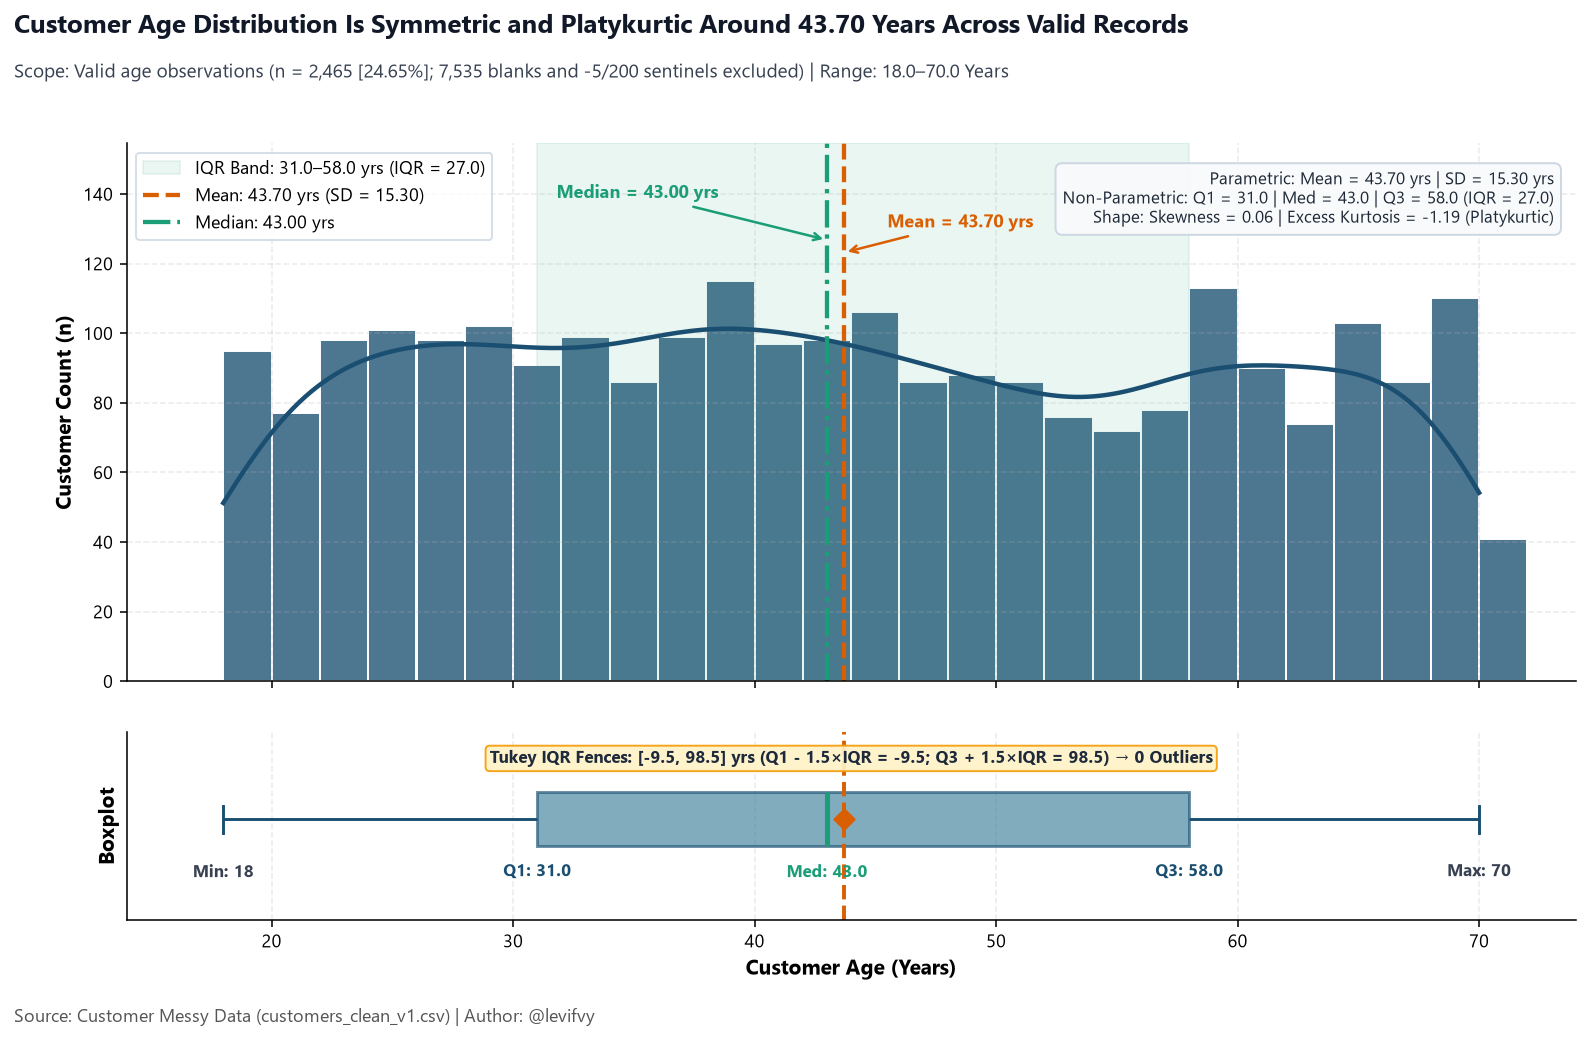

In [7]:
fig_e4_age = plot_e4_age_distribution(df_v1, save=True)
plt.show()
plt.close(fig_e4_age)

**Visual Interpretation — Customer Age Distribution (`Q1` Demographics):**
- Across valid observations ($n = 2,465$, **24.65%** coverage; $7,535$ blank or `-5`/`200` sentinel records excluded to `NaN` rather than single-value median imputation, which would artificially compress `SD` from `15.30` to `~7.6` years), `age` spans **18.0 to 70.0 years** smoothly.
- Parametric (`mean = 43.70` years, `SD = 15.30` years) and non-parametric (`median = 43.00` years, `Q1 = 31.0`, `Q3 = 58.0`, `IQR = 27.0` years) central tendencies converge tightly, with near-zero skewness (`0.06`) and negative excess kurtosis (`-1.19`) confirming a symmetric, platykurtic (near-uniform) adult age profile.
- Formal Tukey fences ($[-9.5,\; 98.5]$ years) lie well outside the observed `[18.0, 70.0]` support, confirming **0 univariate age outliers** after sentinel removal.

Saved figure: assets/charts/e4_univariate_purchase_distribution.png


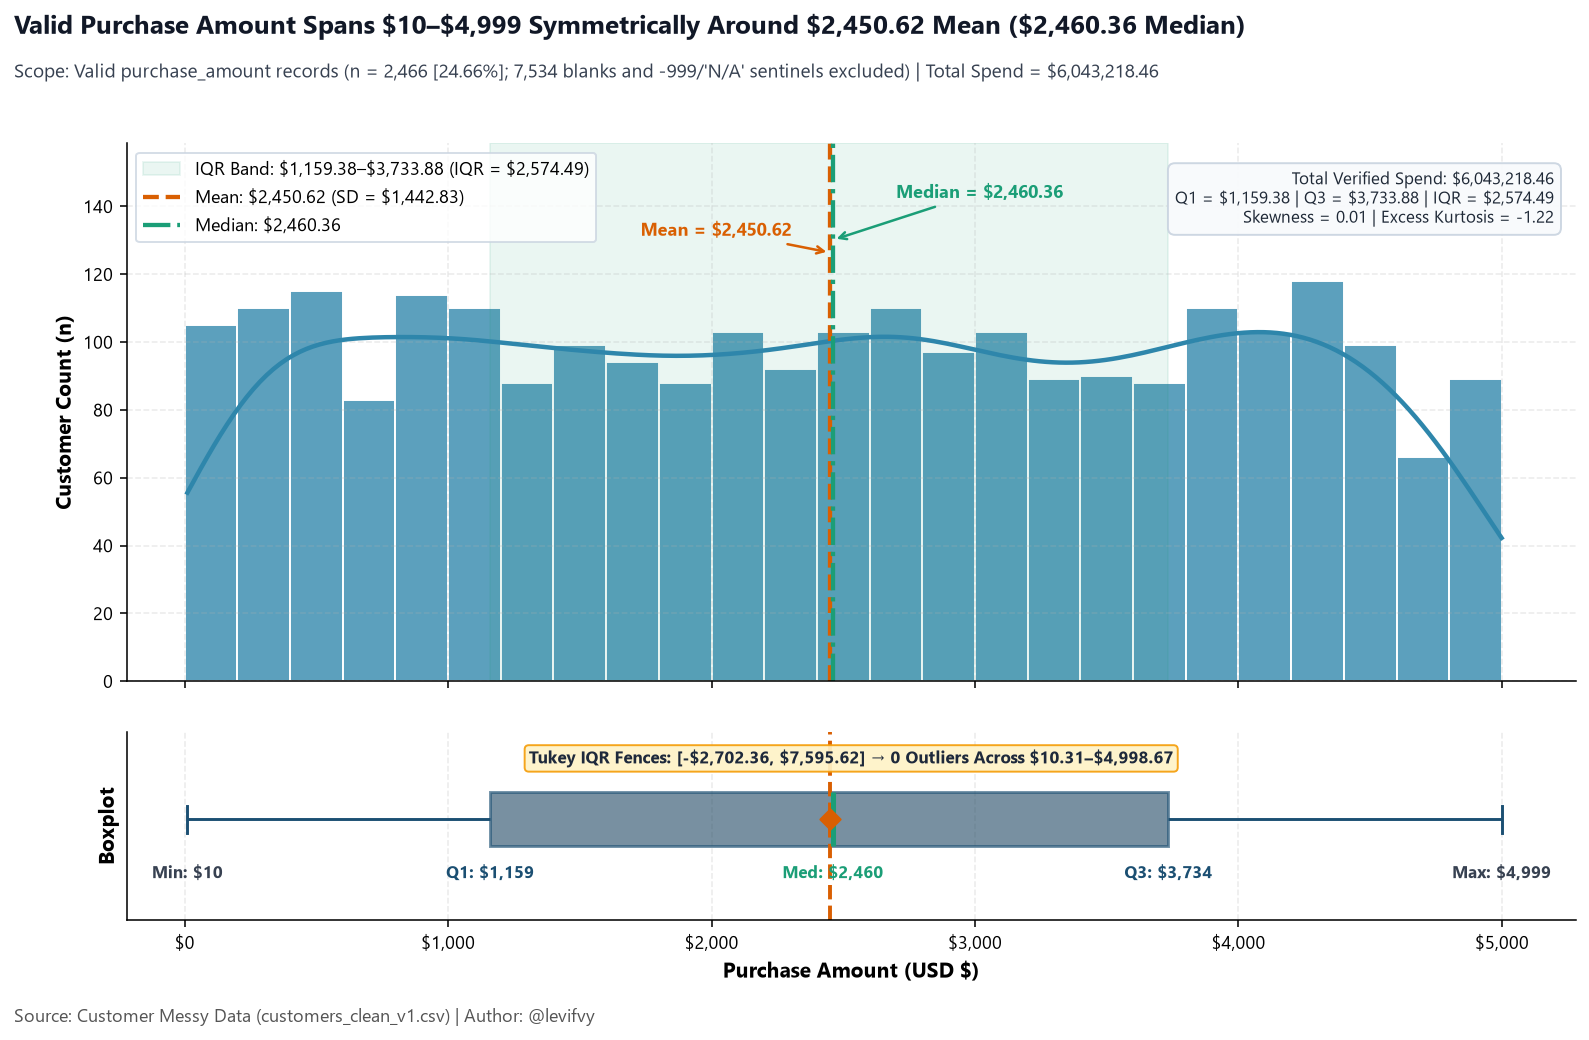

In [8]:
fig_e4_spend = plot_e4_purchase_distribution(df_v1, save=True)
plt.show()
plt.close(fig_e4_spend)

**Visual Interpretation — Transaction Spend Distribution (`Q2` Revenue Distribution):**
- Valid `purchase_amount` covers **24.66%** of accounts ($n = 2,466$; $7,534$ blanks and `-999`/`'N/A'` sentinels excluded), generating **$6,043,218.46** in verified transaction volume across `$10.31–$4,998.67`.
- Both `mean` (**$2,450.62**, `SD = $1,442.83`) and `median` (**$2,460.36**, `Q1 = $1,159.39`, `Q3 = $3,733.88`, `IQR = $2,574.50`) sit virtually at the midpoint of the `$0–$5,000` range (`skewness = 0.01`, excess `kurtosis = -1.22`), demonstrating uniform dispersion across low, mid, and high ticket sizes.
- Formal Tukey fences ($[-\$2,702.36,\; \$7,595.62]$) confirm **0 statistical spend outliers** among valid transactions, meaning top-tier orders (`>$3,500`) represent genuine broad-spectrum demand rather than isolated extreme anomalies.

Saved figure: assets/charts/e4_univariate_demographics_counts.png


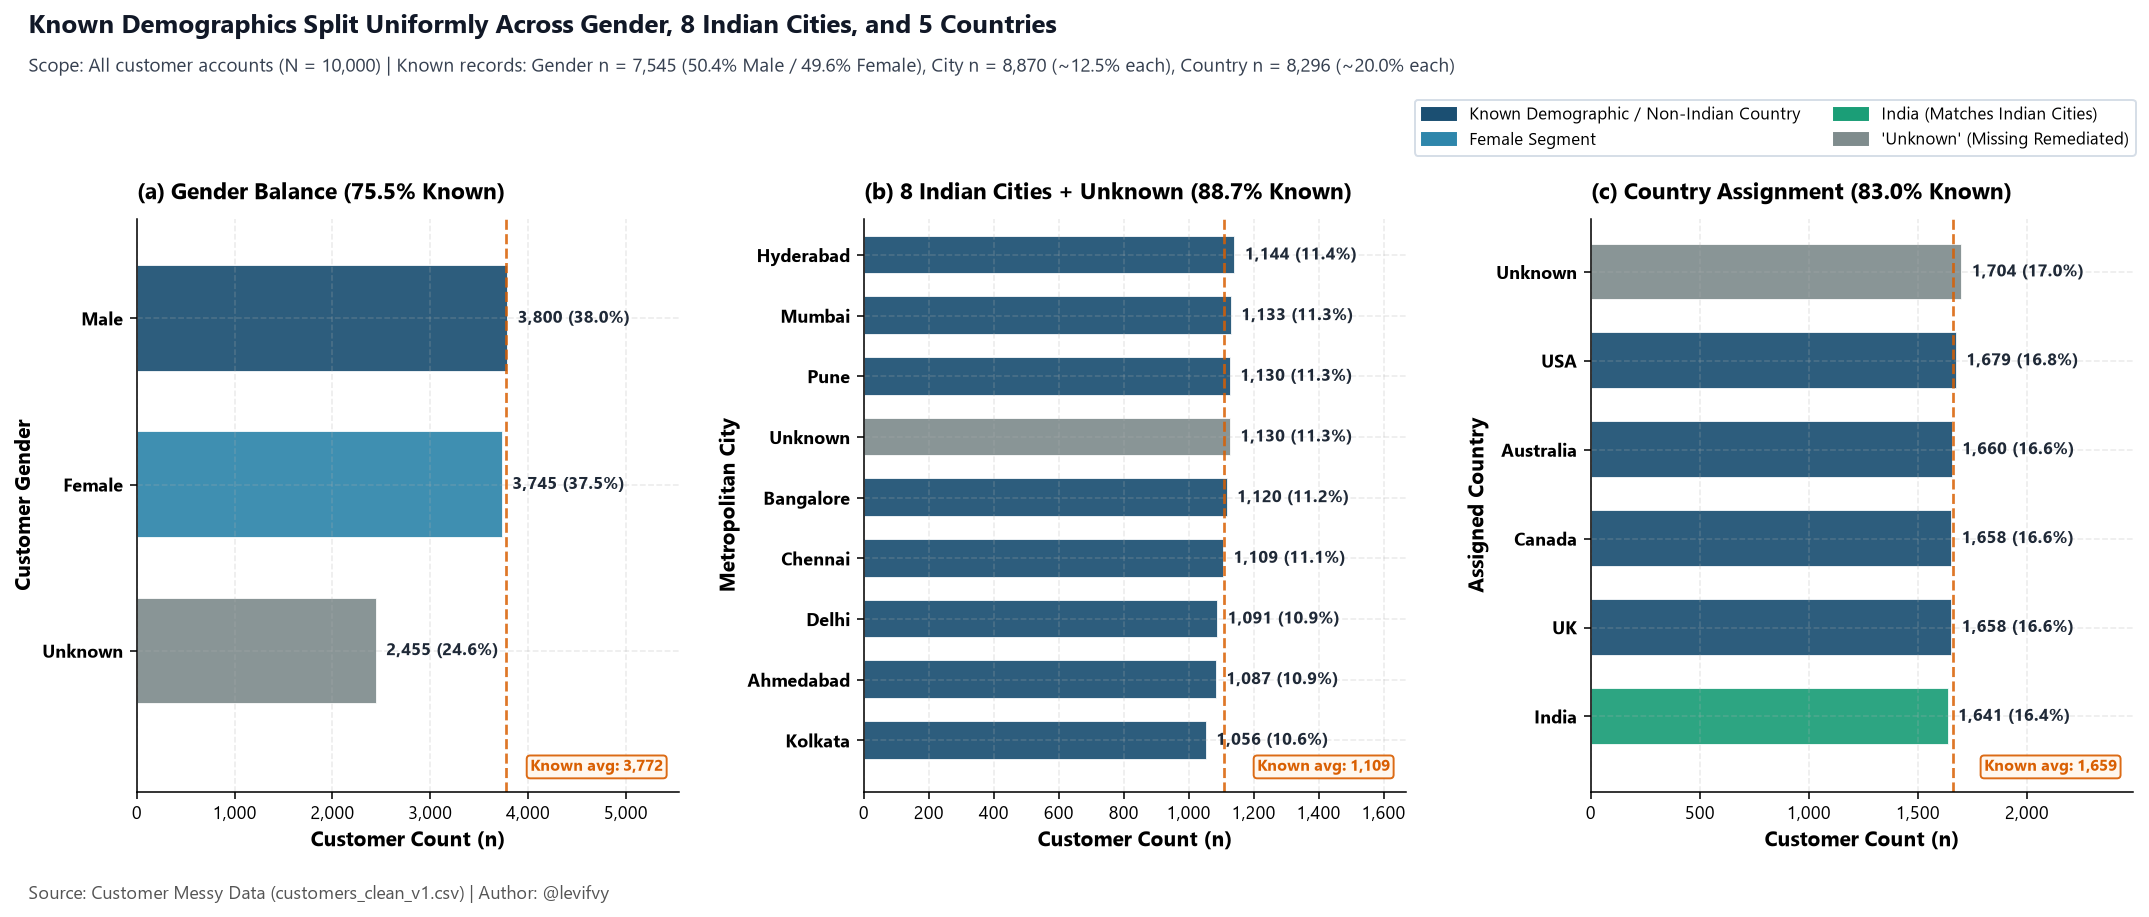

In [9]:
fig_e4_demo = plot_e4_demographics_counts(df_v1, save=True)
plt.show()
plt.close(fig_e4_demo)

**Visual Interpretation — Demographic & Geographic Counts (`Q1` Customer Profile):**
- **Gender (`75.45%` known, $n = 7,545$):** Nearly 50/50 parity between `Male` ($n = 3,800$, `38.0%` total / `50.36%` known) and `Female` ($n = 3,745$, `37.5%` total / `49.64%` known), alongside `2,455` (`24.6%`) `'Unknown'` accounts rendered in slate grey.
- **Metropolitan City (`88.70%` known, $n = 8,870$):** All 8 known cities are major Indian metropolitan hubs (`Hyderabad` `1,144` [`11.4%`] to `Kolkata` `1,056` [`10.6%`], averaging `1,109` accounts per city), with `1,130` (`11.3%`) `'Unknown'`.
- **Assigned Country (`82.96%` known, $n = 8,296$):** `'Unknown'` is the single largest country bucket (`1,704`, `17.0%`), while known entries split uniformly (~`16.4%–16.8%` of total; ~`20.0%` of known) across `USA` (`1,679`), `Australia` (`1,660`), `Canada` (`1,658`), `UK` (`1,658`), and `India` (`1,641`) — foreshadowing the severe city-vs-country geographic contradiction audited in `E5`.

Saved figure: assets/charts/e4_univariate_feedback_reachability.png


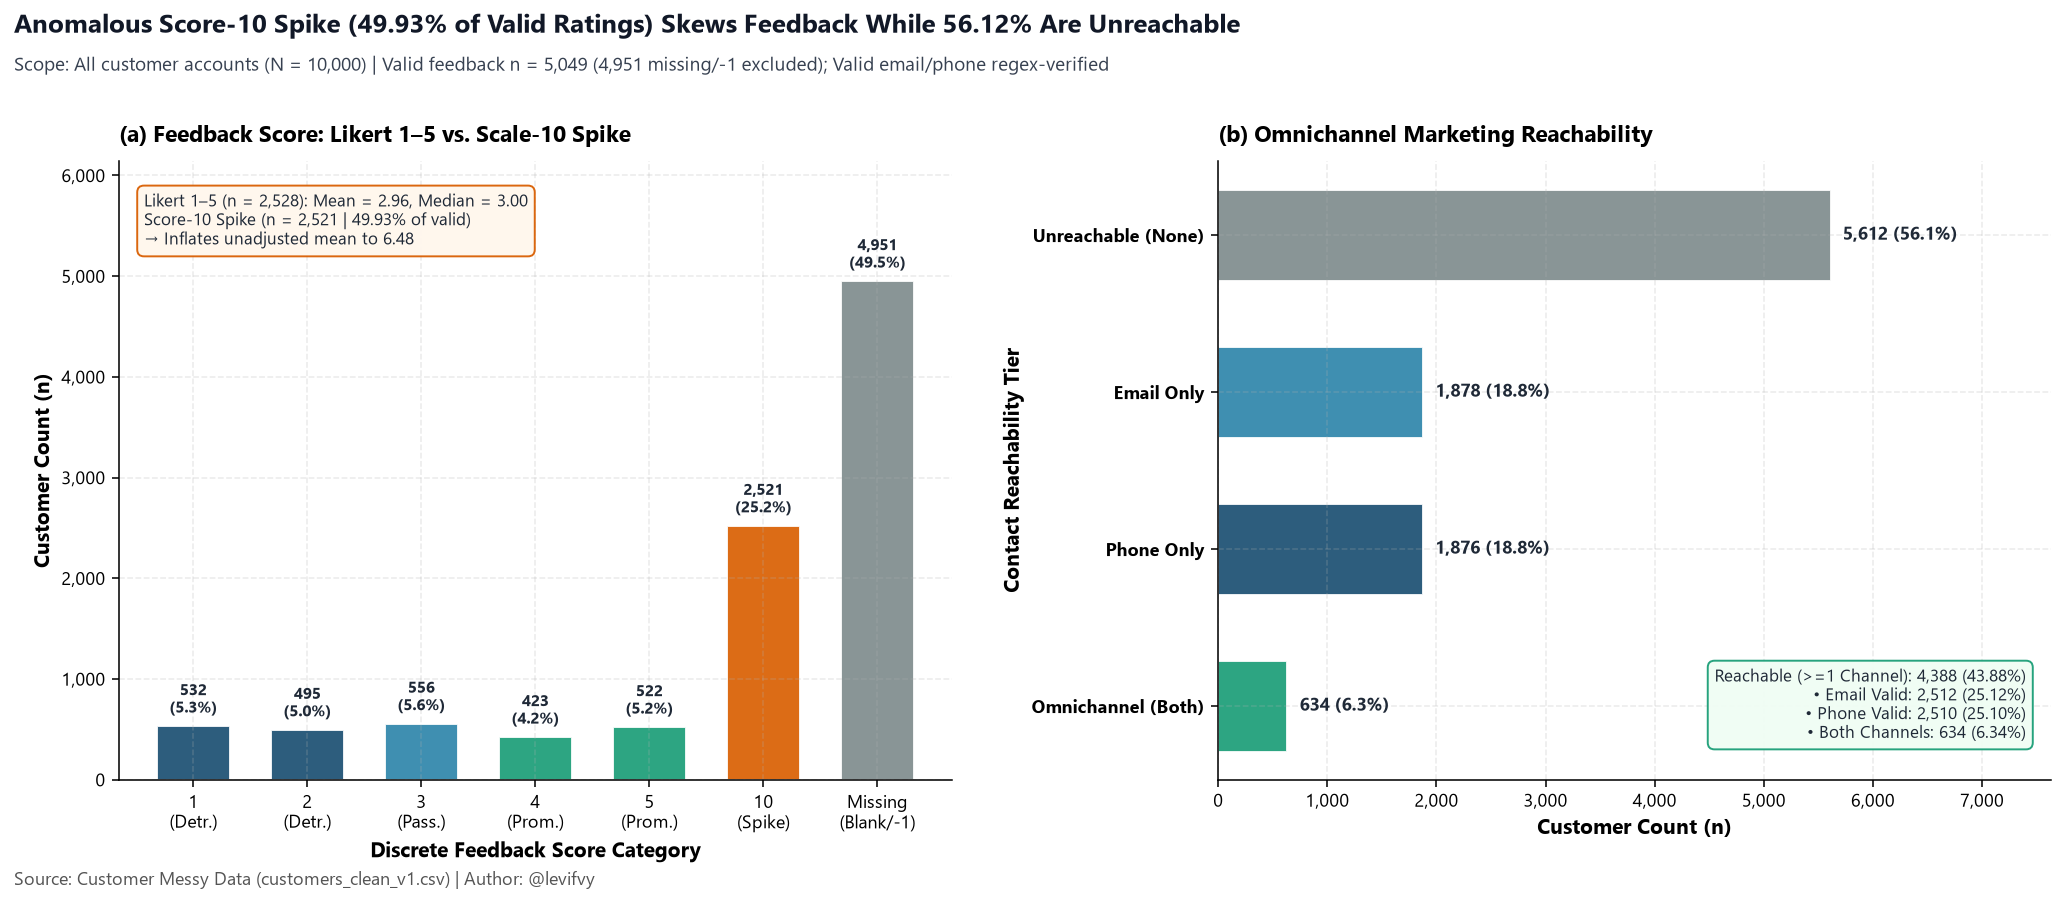

In [10]:
fig_e4_fb = plot_e4_feedback_and_reachability(df_v1, save=True)
plt.show()
plt.close(fig_e4_fb)

**Visual Interpretation — Feedback Scale Distortion & Omnichannel Reachability (`Q3` Satisfaction & Retention):**
- **Bimodal Rating Scale Distortion (`KPI-6`):** Almost half of all accounts (`4,951`, `49.5%`) lack valid feedback (blanks or `-1` sentinel). Among the $n = 5,049$ valid ratings, **2,521 records (`49.93%` of valid; `25.2%` of total)** sit at an off-scale score of `10`, artificially inflating the unadjusted mean to `6.48`. Isolating the clean `1–5` Likert cohort ($n = 2,528$) reveals a balanced, neutral satisfaction baseline (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`), with Detractors (`1–2`: `1,027` [`40.6%` of Likert]) slightly outnumbering Promoters (`4–5`: `945` [`37.4%` of Likert]).
- **Severe Contact Unreachability (`KPI-4`):** Across $N = 10,000$ accounts, **5,612 (`56.12%`) are completely `Unreachable (None)`** due to missing or malformed emails/phone numbers. Only **4,388 (`43.88%`)** can be contacted via at least one verified channel (`1,878` [`18.78%`] `Email Only`, `1,876` [`18.76%`] `Phone Only`, and just `634` [`6.34%`] `Omnichannel (Both)`), creating an immediate CRM bottleneck for retention campaigns.

---

## 5. `[E5]` Bivariate Analysis — Segment Comparisons & Hypothesis Testing

### 5.1 Quantitative Segment Comparisons & Formal Hypothesis Tests

We next evaluate pairwise relationships across three analytical families using `src/analysis.py`:
1. **Continuous × Categorical (`Q2`, `Q3`):** `purchase_amount` compared across `gender`, `country`, `city`, ontology `age_group` cohorts, discrete `feedback_score`, and `contact_reachability` via One-way ANOVA ($F$) and Kruskal-Wallis ($H$) tests (both including and excluding `'Unknown'`/`'Missing'`).
2. **Continuous × Continuous (`Q2`, `Q3`):** Pairwise linear (Pearson $r$) and monotonic rank (Spearman $\rho$) correlations of `age`, `feedback_score_1_to_5`, `feedback_score` (all), and chronologically valid `tenure_days` with `purchase_amount`.
3. **Categorical × Categorical (`Q1`):** `city` × `country` contingency table, Pearson $\chi^2$ test of independence, and exact audit of cross-border geographic mismatches.

In [11]:
e5_seg_spend = compute_bivariate_segment_spend(df_v1)
e5_tests = run_bivariate_hypothesis_tests(df_v1)
e5_crosstab = compute_city_country_crosstab(df_v1)

print("=== [E5] BIVARIATE SEGMENT SPEND SUMMARY ===")
print(e5_seg_spend.round(2).to_string(index=False))

print("\n=== [E5] FORMAL BIVARIATE HYPOTHESIS TESTS (ANOVA / KRUSKAL / CORRELATION / CHI2) ===")
print(e5_tests.round(4).to_string(index=False))

print("\n=== [E5] CITY x COUNTRY CROSS-TABULATION & GEOGRAPHIC MISMATCHES ===")
print(e5_crosstab.round(2).to_string(index=False))

=== [E5] BIVARIATE SEGMENT SPEND SUMMARY ===
                dimension                 segment  n_segment  n_valid_spend  spend_coverage_pct  mean_spend  std_spend  median_spend  q1_spend  q3_spend  iqr_spend  total_spend  revenue_per_1k_valid
                   gender                    Male       3800            960               25.26     2474.16    1471.21       2521.68   1114.59   3808.19    2693.60   2375192.57            2474158.93
                   gender                  Female       3745            889               23.74     2458.40    1438.41       2388.78   1215.44   3787.77    2572.33   2185521.50            2458404.39
                   gender                 Unknown       2455            617               25.13     2402.76    1405.32       2460.06   1181.70   3535.63    2353.93   1482504.39            2402762.38
                  country                     USA       1679            395               23.53     2363.55    1412.40       2327.06   1173.84   3602.56    242

**Quantitative Interpretation (`E5`):**
- **Segment Spend Homogeneity (`Q2`):** Across every demographic, geographic, satisfaction, and reachability dimension, observed `purchase_amount` variations lie well within random sampling noise (`significant_at_0_05 == False` for all 13 categorical comparisons, all $p \ge 0.31$). Specifically, among known segments: `gender` (`Male` mean `$2,474.16` / median `$2,521.69` [$n = 960$] vs. `Female` mean `$2,458.40` / median `$2,388.78` [$n = 889$]; ANOVA $F = 0.0541, p = 0.8161$; Kruskal $H = 0.0481, p = 0.8265$), `country` (ranging from `USA` mean `$2,363.55` [$n = 395$] to `Australia` mean `$2,510.63` [$n = 413$]; $F = 0.6297, p = 0.6413$; $H = 2.5092, p = 0.6430$), `city` (ranging from `Kolkata` mean `$2,286.54` [$n = 264$] to `Chennai` mean `$2,562.51` [$n = 258$]; $F = 0.9386, p = 0.4752$; $H = 6.6429, p = 0.4670$), and `age_group` (ranging from `18-29` mean `$2,334.77` [$n = 134$] to `60+` mean `$2,556.18` [$n = 117$]; $F = 0.5038, p = 0.6798$; $H = 1.6209, p = 0.6547$) show no statistically significant differentiation.
- **Zero Linear or Monotonic Association with Spend (`Q2`, `Q3`):** Pairwise correlations with `purchase_amount` are near zero across `age` ($n = 600$, $r = 0.0430 [p = 0.2930]$, $\rho = 0.0457 [p = 0.2641]$), `feedback_score_1_to_5` ($n = 648$, $r = -0.0178 [p = 0.6508]$, $\rho = -0.0168 [p = 0.6688]$), all valid `feedback_score` ($n = 1,248$, $r = 0.0174 [p = 0.5384]$, $\rho = 0.0168 [p = 0.5527]$), and valid `tenure_days` ($n = 219$, $r = -0.0560 [p = 0.4098]$, $\rho = -0.0700 [p = 0.3027]$). Observational correlations neither indicate statistical dependence nor imply causal effects.
- **Structural Geographic Contradiction (`Q1`):** Although all 8 known cities (`Hyderabad`, `Mumbai`, `Pune`, `Bangalore`, `Chennai`, `Delhi`, `Ahmedabad`, `Kolkata`) are Indian metropolitan areas, `city` and `country` are statistically independent ($\chi^2 = 32.1845, \text{dof} = 40, p = 0.8057$ across all $10,000$ rows; $\chi^2 = 19.2934, \text{dof} = 28, p = 0.8888$ across $7,348$ dual-known rows). Consequently, **5,888 records** (`58.88%` of the entire dataset; **80.13%** of the $7,348$ dual-known city-country records) pair an Indian city with `USA`, `Australia`, `Canada`, or `UK` (`63.85%–69.03%` row mismatch across every Indian city).

### 5.2 Bivariate Visual Exploration — Segment Homogeneity, Correlation & Geographic Integrity

To test whether transaction value clusters within specific demographic, geographic, age, satisfaction, or reachability cohorts — and to visually audit cross-column geographic consistency — we generate four multi-panel bivariate diagnostics (`src/visualization.py`).

Saved figure: assets/charts/e5_bivariate_spend_by_demographics.png


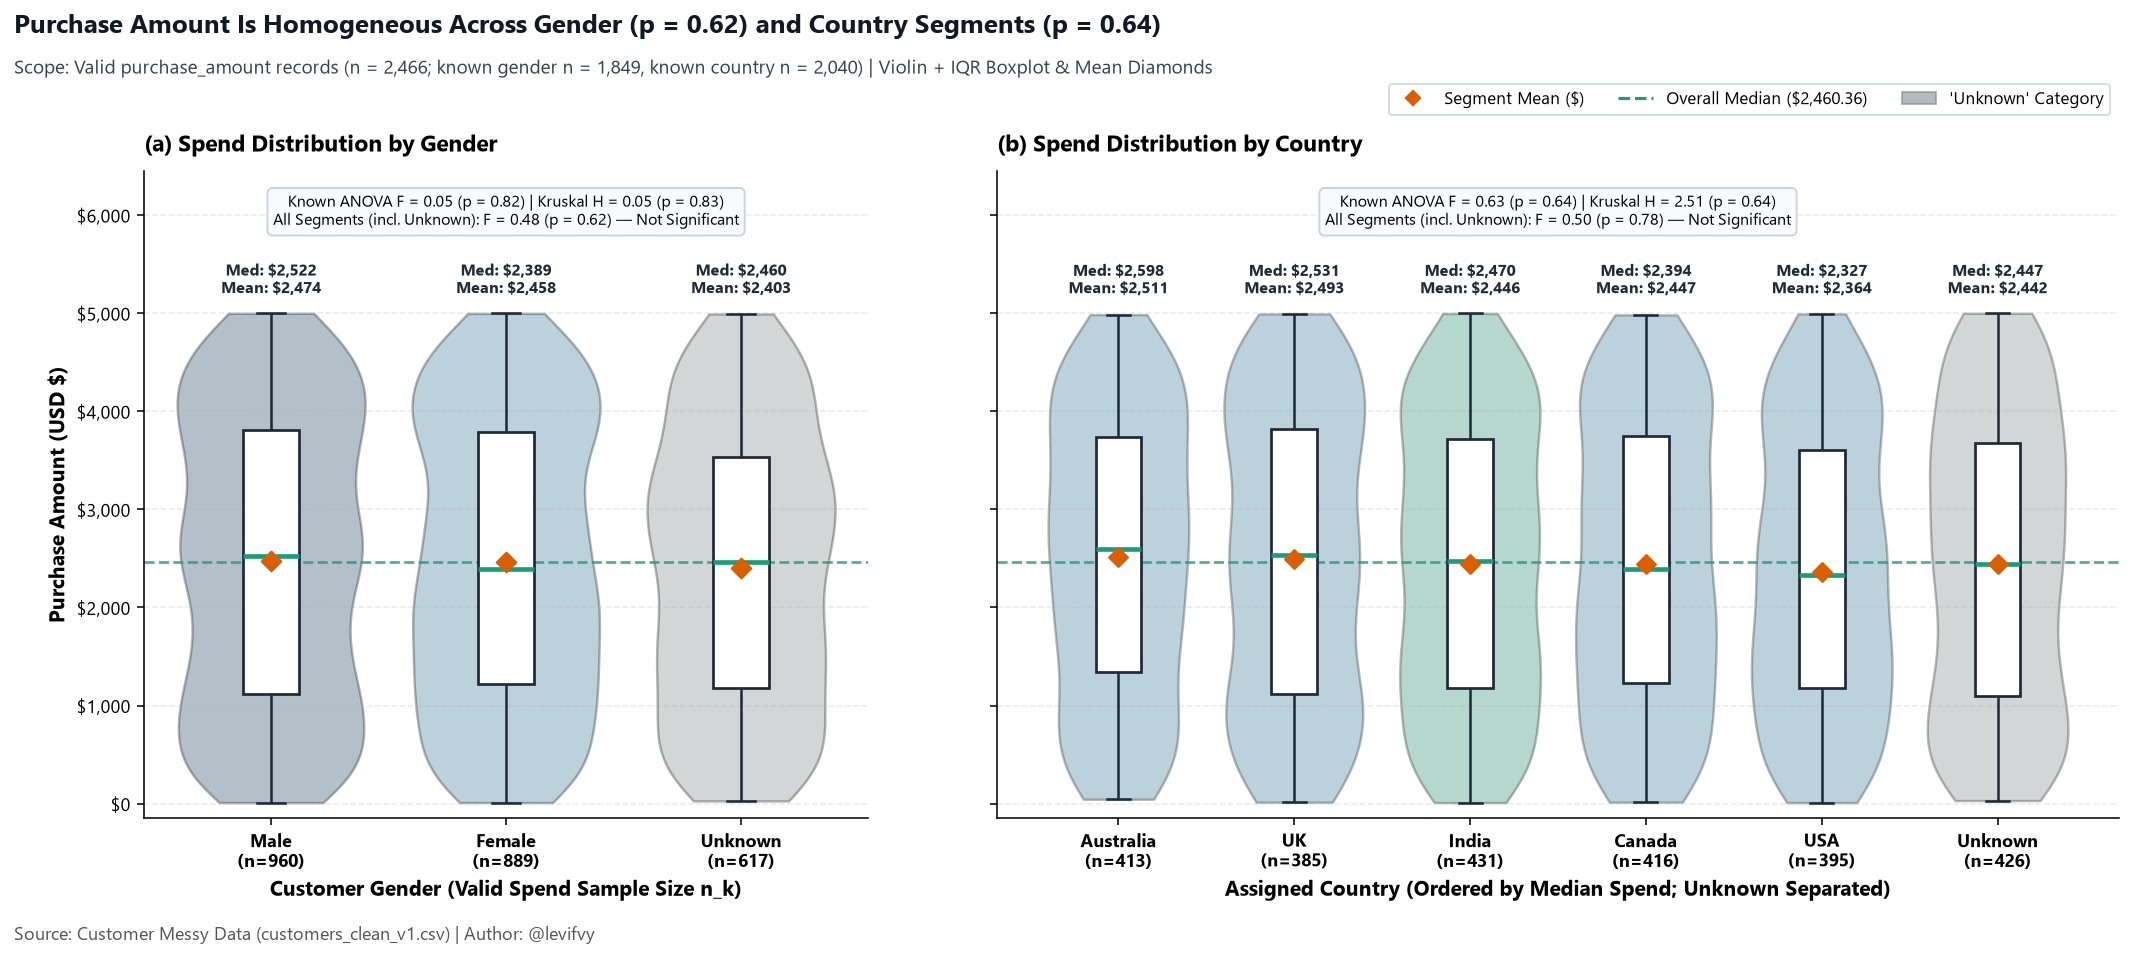

In [12]:
fig_e5_demo = plot_e5_spend_by_demographics(df_v1, save=True)
plt.show()
plt.close(fig_e5_demo)

**Visual Interpretation — Spend by Gender & Country (`Q2` High-Value Segments):**
- **Gender Homogeneity:** Across $n = 2,466$ valid spenders, violin densities and IQR boxes align closely across `Male` ($n_k = 960$, `mean = $2,474.16`, `median = $2,521.69`), `Female` ($n_k = 889$, `mean = $2,458.40`, `median = $2,388.78`), and `'Unknown'` ($n_k = 617$, `mean = $2,402.76`, `median = $2,460.06`). Neither known-gender tests (`ANOVA F = 0.05, p = 0.82`; `Kruskal-Wallis H = 0.05, p = 0.83`) nor all-segment tests (`F = 0.48, p = 0.62`) approach statistical significance.
- **Country Homogeneity:** Ordering countries by median spend from `Australia` ($n_k = 413$, `median = $2,597.60`, `mean = $2,510.63`) down to `USA` ($n_k = 395$, `median = $2,327.06`, `mean = $2,363.55`) — alongside `India` ($n_k = 431$, `median = $2,469.79`) and `'Unknown'` ($n_k = 426$, `median = $2,446.78`) — shows nearly identical platykurtic spreads (`known ANOVA F = 0.63, p = 0.64`; `Kruskal H = 2.51, p = 0.64`; `all-segment p = 0.78`).

Saved figure: assets/charts/e5_bivariate_spend_by_city_age.png


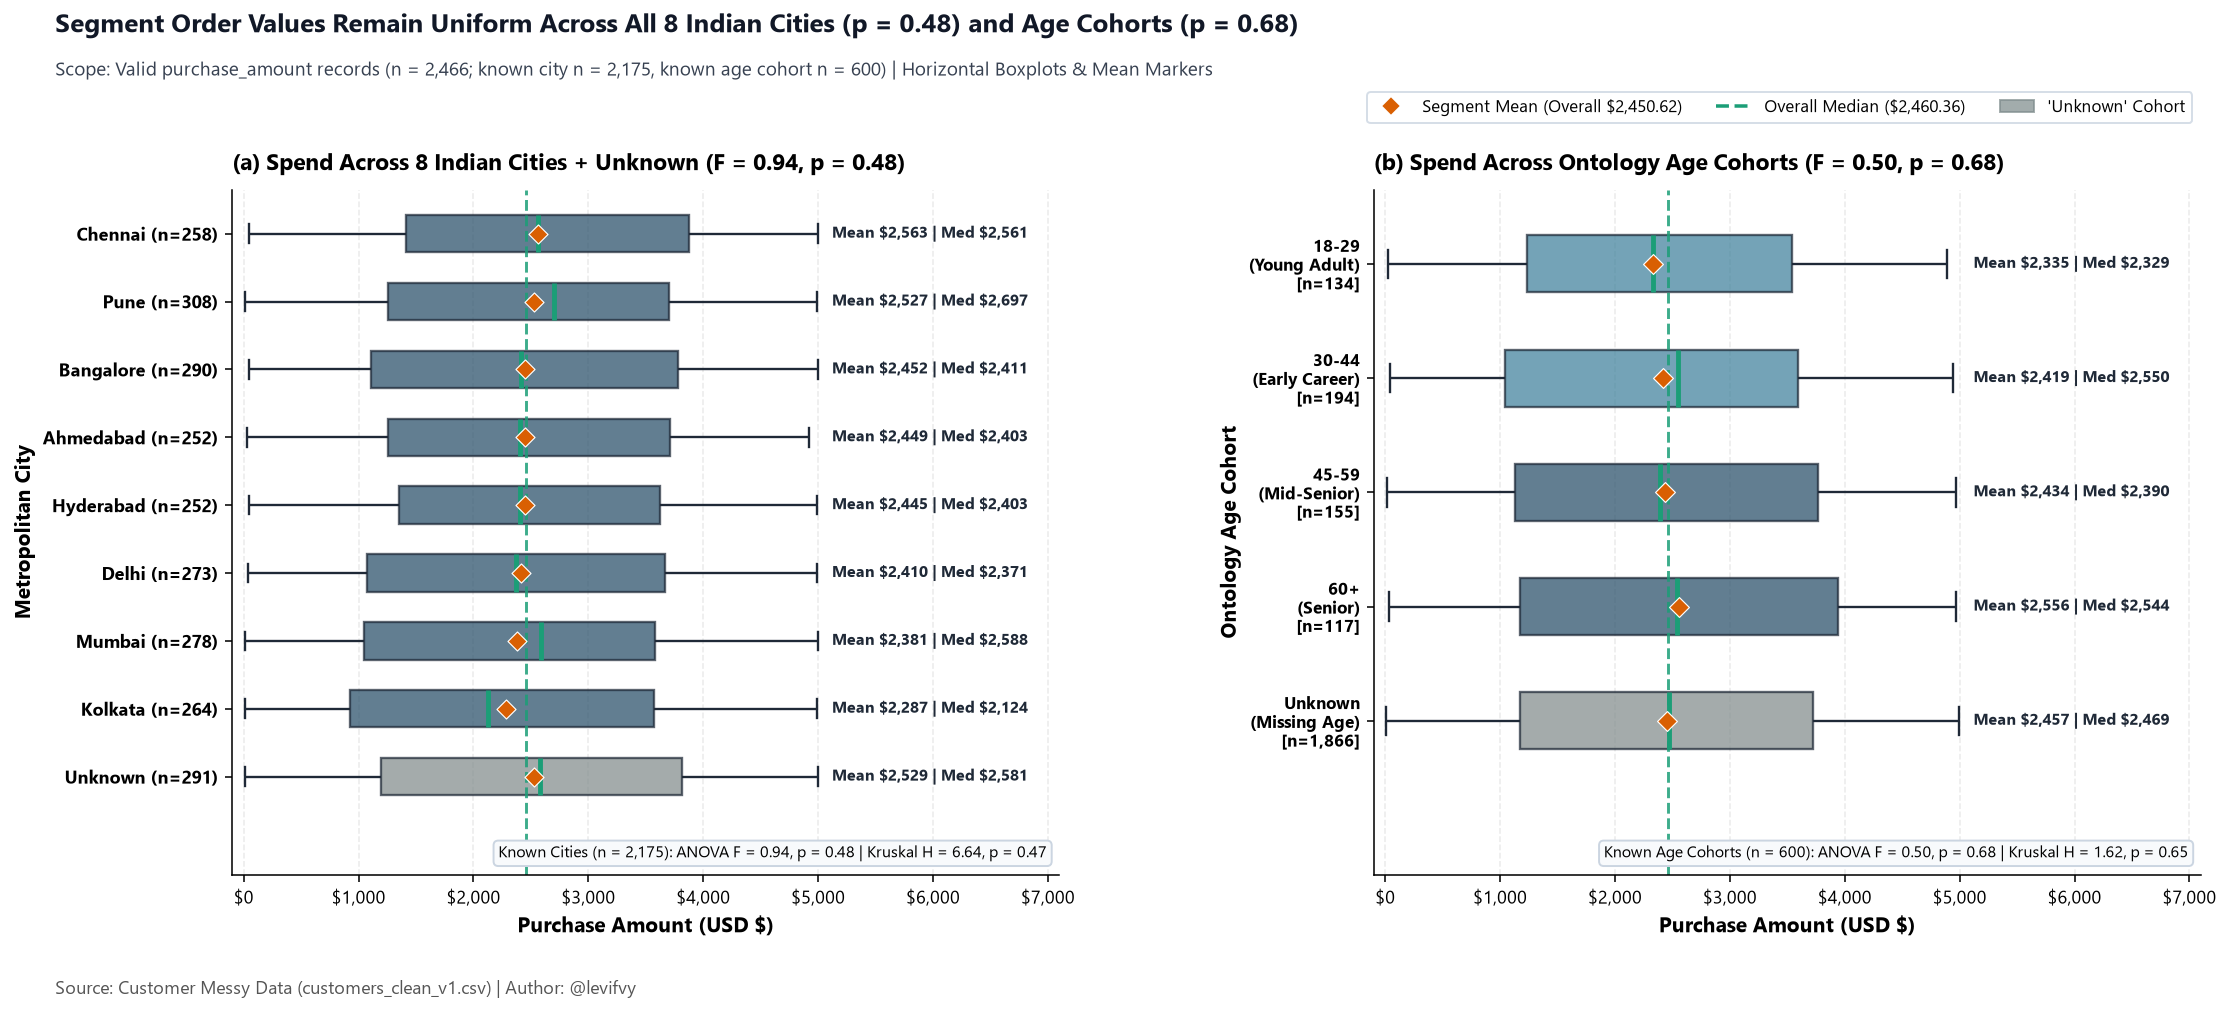

In [13]:
fig_e5_city_age = plot_e5_spend_by_city_and_age(df_v1, save=True)
plt.show()
plt.close(fig_e5_city_age)

**Visual Interpretation — Spend Across Indian Cities & Ontology Age Cohorts (`Q2` High-Value Segments):**
- **Metropolitan Cities ($n = 2,175$ known; $n = 2,466$ total):** Segment means span a narrow band from `Chennai` (`$2,562.51`, `median = $2,561.14`, $n_k = 258$) and `Pune` (`$2,526.88`, `median = $2,697.49`, $n_k = 308$) to `Kolkata` (`$2,286.54`, `median = $2,124.33`, $n_k = 264$), with `'Unknown'` at `$2,529.39` ($n_k = 291$). Formal omnibus tests (`known ANOVA F = 0.94, p = 0.48`; `Kruskal H = 6.64, p = 0.47`) confirm observed rank differences reflect random sampling variation rather than structural city-level spend premiums.
- **Ontology Age Cohorts ($n = 600$ known; $n = 1,866$ `'Unknown'`):** Comparing `18-29 (Young Adult)` (`mean = $2,334.77`, $n_k = 134$), `30-44 (Early Career)` (`$2,418.87`, $n_k = 194$), `45-59 (Mid-Senior)` (`$2,433.83`, $n_k = 155$), and `60+ (Senior)` (`$2,556.18`, $n_k = 117$) yields `ANOVA F = 0.50, p = 0.68` (`Kruskal H = 1.62, p = 0.65`), confirming that customer age brackets do not segment order value; moreover, `'Unknown'` age accounts ($n_k = 1,866$, `mean = $2,457.01`) match known-age spend (`all-segment p = 0.80`), supporting unbiased `NaN` retention.

Saved figure: assets/charts/e5_bivariate_age_vs_spend.png


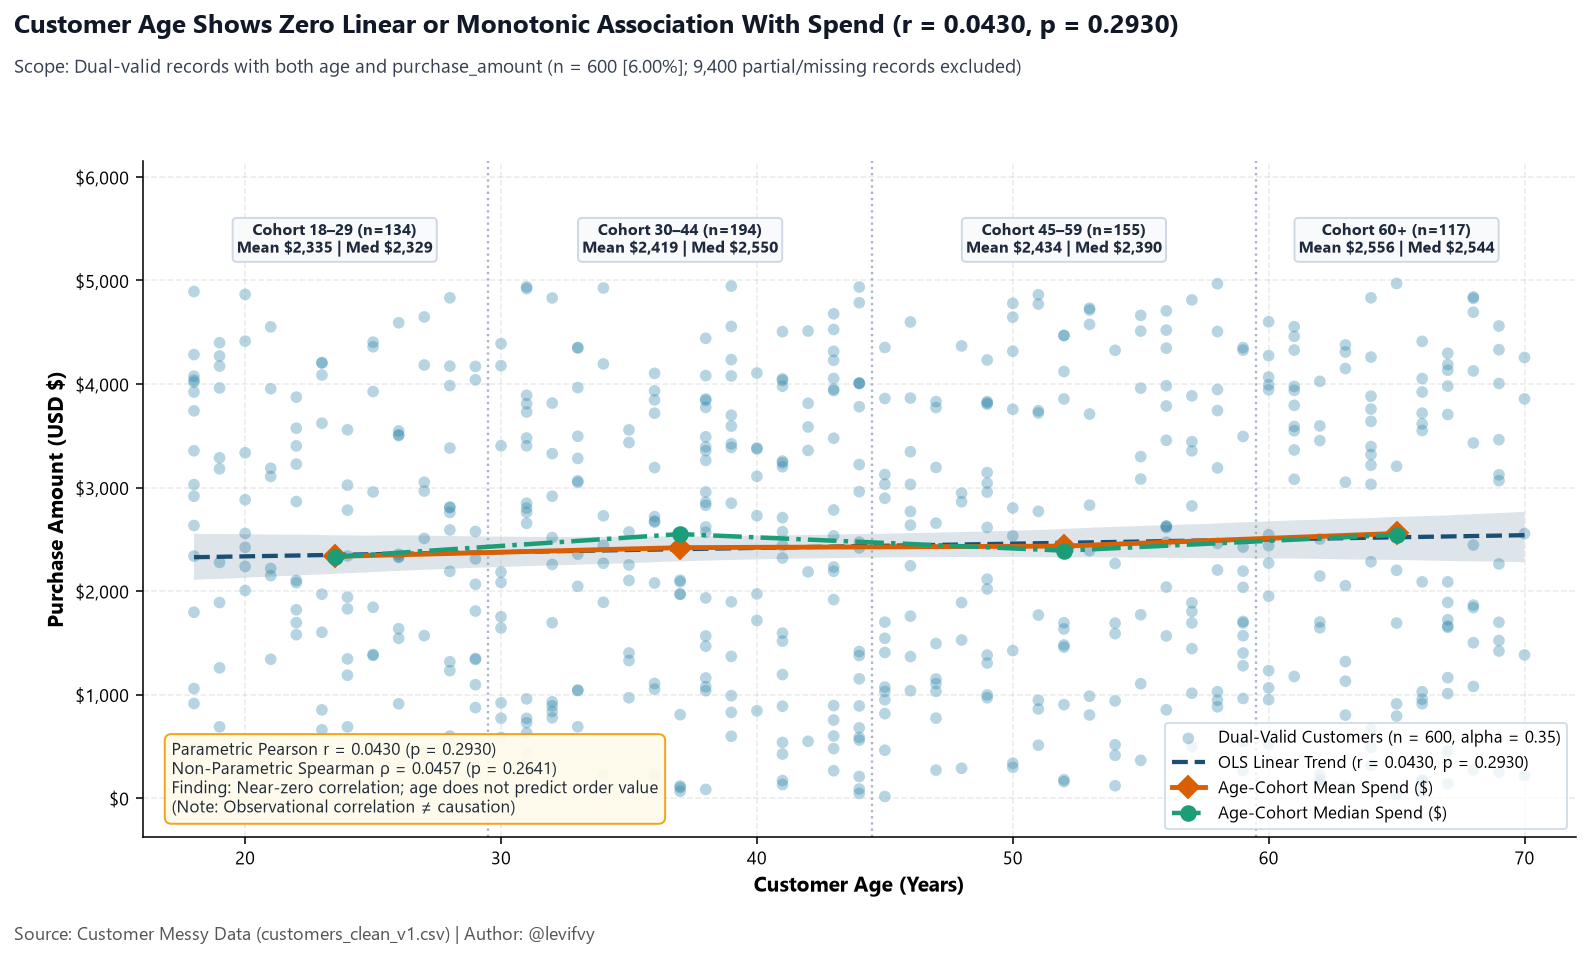

In [14]:
fig_e5_scatter = plot_e5_age_vs_spend(df_v1, save=True)
plt.show()
plt.close(fig_e5_scatter)

**Visual Interpretation — Continuous Age vs. Purchase Amount (`Q2` Revenue Drivers):**
- Plotting all $n = 600$ dual-valid customer records (`6.00%` of dataset; $9,400$ missing `age` and/or `purchase_amount`) with `alpha = 0.35` transparency reveals a uniform rectangular cloud across `18–70` years and `$10–$4,999`.
- Both the OLS linear regression line (`Pearson r = 0.0430, p = 0.2930`) and rank-order association (`Spearman ρ = 0.0457, p = 0.2641`) are flat, and the overlaid cohort mean/median trajectories remain anchored near `~$2,450`. Observational correlation is statistically indistinguishable from zero (and, per statistical governance, implies no causal relationship).

Saved figure: assets/charts/e5_bivariate_feedback_and_geo_mismatch.png


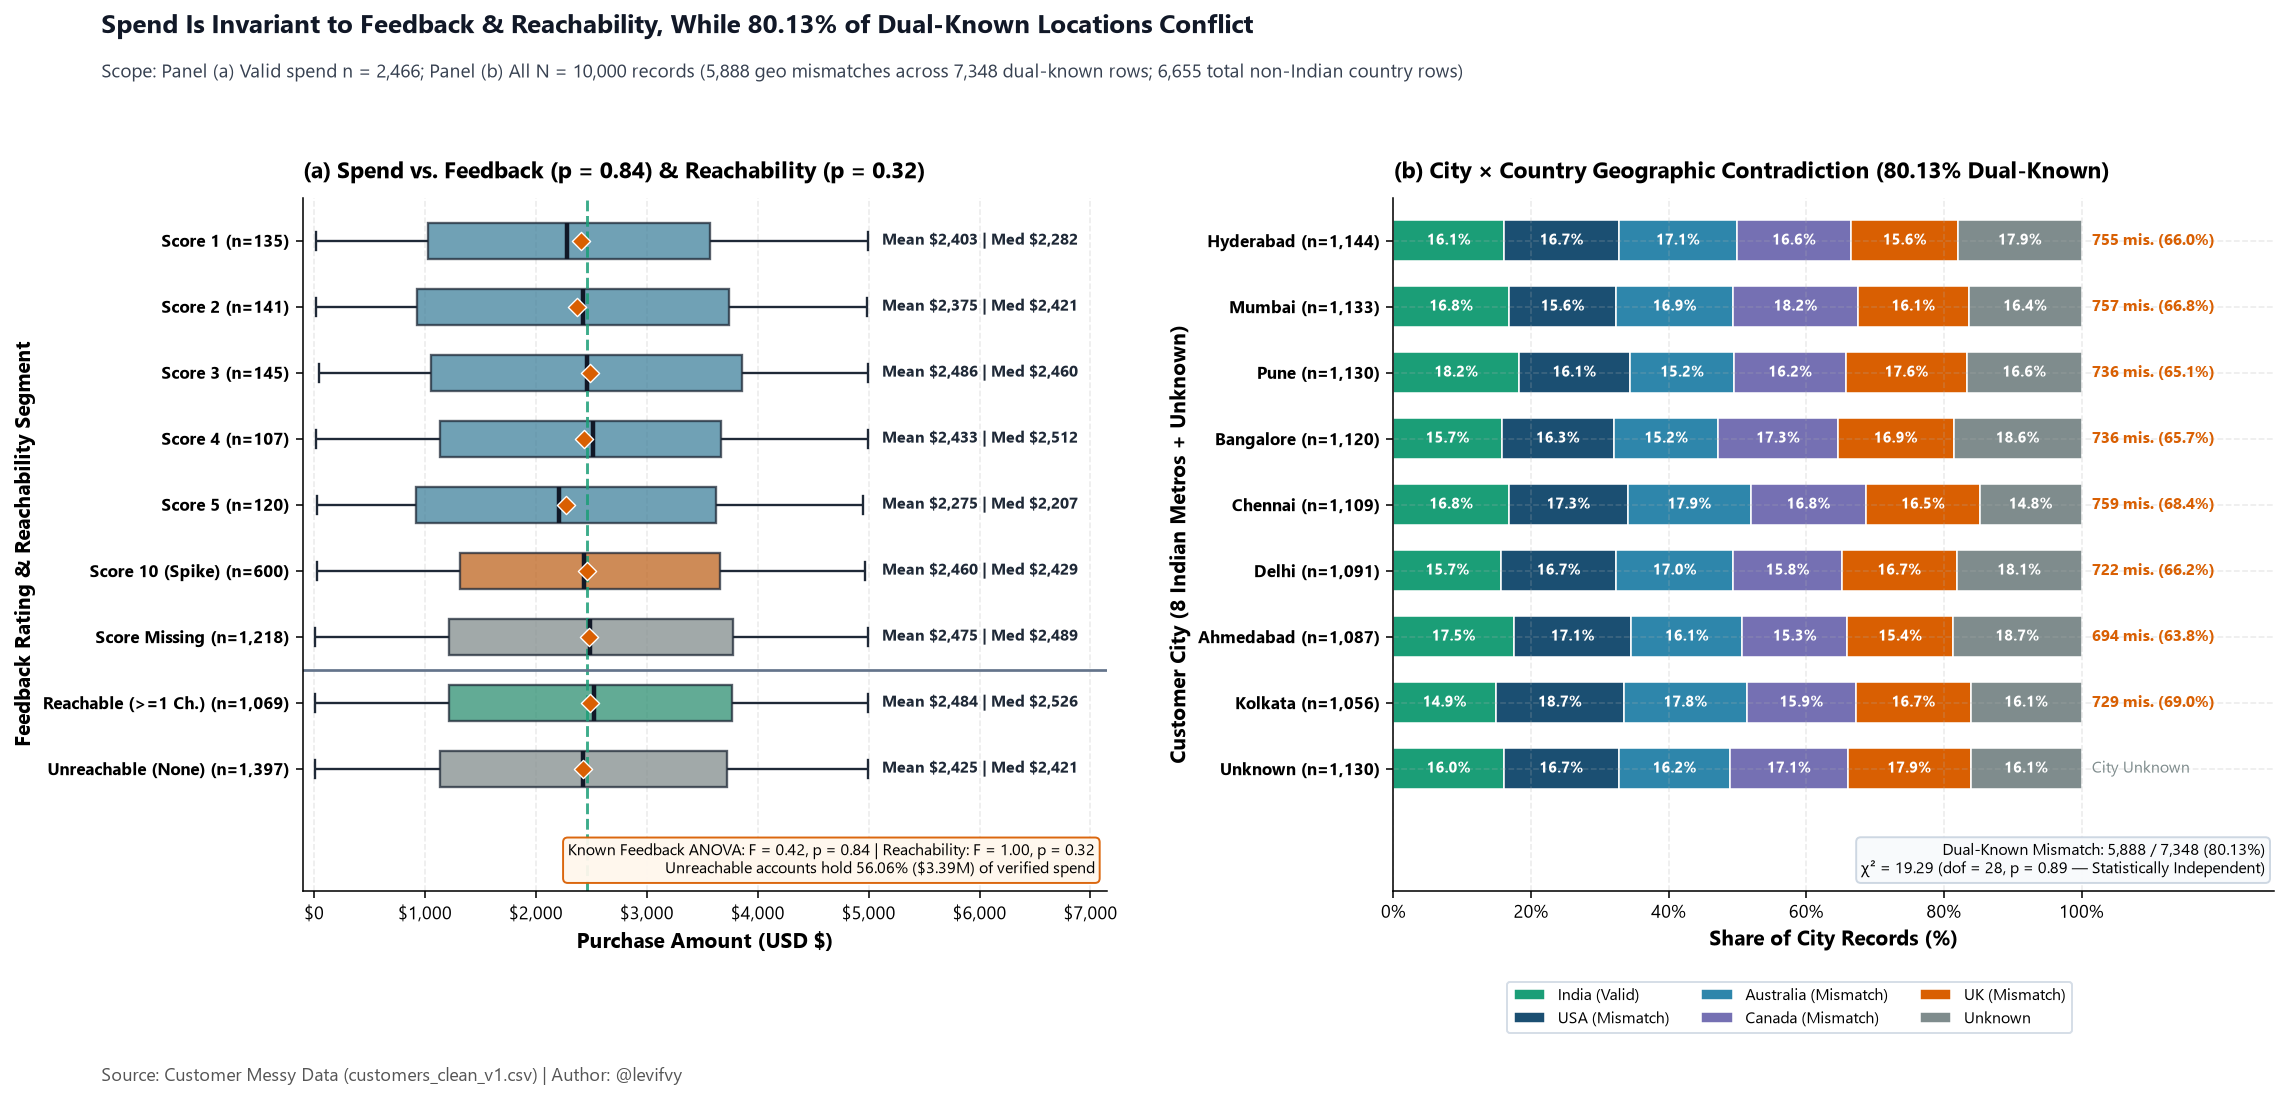

In [15]:
fig_e5_diag = plot_e5_feedback_and_geo_mismatch(df_v1, save=True)
plt.show()
plt.close(fig_e5_diag)

**Visual Interpretation — Feedback/Reachability Spend Invariance (`Q3`) & City × Country Contradiction (`Q1`):**
- **Panel (a) — Satisfaction & Reachability vs. Spend (`Q3`):** Order values do not vary across discrete `feedback_score` ratings `1–5` and the `Score 10` spike (`known ANOVA F = 0.42, p = 0.84`; `Score 10` mean `$2,460.06` [$n_k = 600$] vs. `Likert 1–5` ratings ranging `$2,275–$2,486`), indicating high spenders are just as likely to be Detractors as Promoters. Crucially, `Reachable (>=1 Ch.)` customers ($n_k = 1,069$, `mean = $2,483.83`) and `Unreachable (None)` customers ($n_k = 1,397$, `mean = $2,425.20`) spend equivalently (`F = 1.00, p = 0.32`), exposing **$3,388,004.29 (`56.06%` of verified revenue)** locked inside accounts that marketing cannot currently contact.
- **Panel (b) — Structural Geographic Contradiction (`Q1`):** Although every known city (`Hyderabad`, `Mumbai`, `Pune`, `Bangalore`, `Chennai`, `Delhi`, `Ahmedabad`, `Kolkata`) is located in India, each city row distributes ~`15%–19%` of its records uniformly across `India`, `USA`, `Australia`, `Canada`, `UK`, and `Unknown` (`χ² = 19.29, dof = 28, p = 0.89` across $n = 7,348$ dual-known rows — complete statistical independence). This synthetic/corrupted country assignment generates **5,888 exact `is_geo_mismatch` records** (**80.13%** of `7,348` dual-known records; **58.88%** of all `10,000` records, out of `6,655` total non-Indian country rows including `767` with `'Unknown'` city).

---

## 6. `[E6]` Answers to Guiding Business Questions & Essential Level Conclusions

To close the Essential EDA milestone (`E1–E6`), we first compute the consolidated canonical KPI table (`KPI-1` through `KPI-6` per `specs/ontology.md` §4) via `src/analysis.py` and then synthesize evidence-backed answers to `Q1`, `Q2`, and `Q3`.

In [16]:
e6_kpis = compute_research_question_kpis(df_v1)

print("=== [E6] CANONICAL RESEARCH QUESTION KPI SUMMARY (KPI-1 TO KPI-6) ===")
print(e6_kpis.round(2).to_string(index=False))

=== [E6] CANONICAL RESEARCH QUESTION KPI SUMMARY (KPI-1 TO KPI-6) ===
kpi_id business_question                                       kpi_name                                                               indicator  n_numerator  n_denominator  primary_value              unit  secondary_value               secondary_metric                                                                                                                                  notes
 KPI-1                Q1              Valid Attribute Coverage Rate (%)                                                      Age Valid Coverage         2465          10000          24.65               pct            43.70                 mean_age_years                                                                                             Median age=43.00y, SD=15.30y (range 18-70)
 KPI-1                Q1              Valid Attribute Coverage Rate (%)              Demographics & Location Coverage (Gender / City / Country)         88

### 6.1 Evidence-Backed Answers to the Three Guiding Business Questions (`Q1`, `Q2`, `Q3`)

Building on the univariate profiles (`E4`), bivariate hypothesis tests (`E5`), and canonical KPI consolidation (`KPI-1` through `KPI-6` in `e6_research_questions_kpis.csv`), we answer the three guiding business questions below. Because raw ingestion defects affected roughly three-quarters of continuous records, every conclusion states valid data coverage upfront and anchors exclusively to verified observations (`N = 10,000` cleaned accounts in `customers_clean_v1.csv`).

---

#### `Q1` — Customer Demographics & Geographic Footprint (`KPI-1`)

**Answer:** Among customers with verified demographic records (valid `age` coverage is `24.65%`, $n = 2,465$; known `gender` coverage is `75.45%`, $n = 7,545$), the active customer base is gender-balanced and evenly distributed across adult working ages (`18–70` years, centered near `43` years). However, while known `city` records (`88.70%` coverage, $n = 8,870$) consist exclusively of eight Indian metropolitan areas, reported `country` labels (`82.96%` coverage, $n = 8,296$) are statistically independent of city, leaving **80.13%** of dual-known geographic profiles with a cross-border contradiction.

- **Quantitative Evidence:**
  - **Adult Age Distribution (`KPI-1`, `e4_univariate_numeric_stats.csv`):** Valid `age` is available for $n = 2,465$ of $10,000$ accounts (`24.65%` coverage; $7,535$ records [`75.35%`] contained blanks [`2,576`] or impossible sentinels `-5` [`2,506`] and `200` [`2,453`], remediated to `NaN`). Verified ages span `18.00` to `70.00` years in a flat, symmetric spread: `mean = 43.70` years (`SD = 15.30` years, standard deviation around the mean) and `median = 43.00` years (`IQR = 27.00` years, interquartile range covering the middle 50% from `Q1 = 31.00` to `Q3 = 58.00`; `skewness = 0.0602`).
  - **Gender Parity & Metropolitan Balance (`KPI-1`, `e4_univariate_categorical_counts.csv`):** Standardized `gender` ($n = 7,545$ known; $2,455$ [`24.55%`] `'Unknown'`) is evenly split between `Male` ($n = 3,800$, `50.36%` of known / `38.00%` of total) and `Female` ($n = 3,745$, `49.64%` of known / `37.45%` of total). Known `city` ($n = 8,870$; $1,130$ [`11.30%`] `'Unknown'`) is uniformly distributed across eight Indian metros, ranging from `Kolkata` ($n = 1,056$, `11.91%` of known) to `Hyderabad` ($n = 1,144$, `12.90%` of known).
  - **Structural Geographic Mismatch (`KPI-1`, `e5_city_country_crosstab.csv`, `e5_bivariate_hypothesis_tests.csv`):** Known `country` ($n = 8,296$; $1,704$ [`17.04%`] `'Unknown'`) is split almost equally (~`20%` of known each) across `USA` ($1,679$), `Australia` ($1,660$), `Canada` ($1,658$), `UK` ($1,658$), and `India` ($1,641$), totaling $6,655$ non-Indian country rows (`767` with `'Unknown'` city). Across the $n = 7,348$ accounts where both `city` and `country` are known, **5,888 accounts (`80.13%` of dual-known; `58.88%` of all $10,000$ accounts)** pair an Indian metro with `USA`, `Australia`, `Canada`, or `UK` (`63.85%` to `69.03%` row mismatch in every city). A Pearson Chi-square test of categorical independence confirms no association between reported `city` and `country` ($\chi^2 = 19.2934, \text{dof} = 28, p = 0.8888$ on $n = 7,348$ dual-known records; $\chi^2 = 32.1845, \text{dof} = 40, p = 0.8057$ across all $10,000$ records). **Operational Recommendation (Data Engineering / CRM):** Enforce a lookup-table constraint linking `city` to `country` at account registration and treat `city` (not `country`) as the primary geographic reporting key until historical country labels are reconciled.
- **Cited Charts:** [`e4_univariate_age_distribution.png`](../assets/charts/e4_univariate_age_distribution.png), [`e4_univariate_demographics_counts.png`](../assets/charts/e4_univariate_demographics_counts.png), [`e5_bivariate_feedback_and_geo_mismatch.png`](../assets/charts/e5_bivariate_feedback_and_geo_mismatch.png).
- **Data Quality Caveat:** Because `75.35%` of `age` values are missing after sentinel removal, single-value median imputation was intentionally rejected to avoid compressing age dispersion (`SD` would drop artificially from `15.30` to `7.60` years); additionally, `is_geo_mismatch` (`5,888` rows) invalidates unadjusted country-level market sizing.

---

#### `Q2` — Revenue Distribution & High-Value Segments (`KPI-2`, `KPI-3`)

**Answer:** Verified `purchase_amount` is available for **24.66%** of accounts ($n = 2,466$), totaling **`$6,043,218.46`** with a symmetric, wide transaction spread centered at a mean of **`$2,450.62`** and a median of **`$2,460.36`**. Formal parametric and non-parametric hypothesis tests show **no statistically significant spending differences** across gender, country, city, or age cohorts, indicating that high-value purchasing behavior is distributed uniformly across demographic and geographic groups rather than concentrated in a specific demographic niche.

- **Quantitative Evidence:**
  - **Order Value & Normalized Revenue Baseline (`KPI-2`, `KPI-3`, `e4_univariate_numeric_stats.csv`, `e6_research_questions_kpis.csv`):** Across $n = 2,466$ valid orders (`24.66%` coverage; $7,534$ rows [`75.34%`] were blank [`2,500`], `'N/A'` [`2,533`], or `-999` [`2,501`]), verified revenue totals **`$6,043,218.46`**. Order values span `$10.31` to `$4,998.67` symmetrically (`skewness = 0.0139`), with parametric `mean = $2,450.62` (`SD = $1,442.83`) and non-parametric `median = $2,460.36` (`IQR = $2,574.50`, middle 50% spread from `Q1 = $1,159.39` to `Q3 = $3,733.88`). Normalized **KPI-3** stands at **`$2,450,615.76` per 1,000 valid customers**.
  - **Demographic & Geographic Spend Homogeneity (`KPI-3`, `e5_bivariate_spend_by_segment.csv`, `e5_bivariate_hypothesis_tests.csv`):** Neither One-way ANOVA ($F$, comparing group means) nor Kruskal-Wallis ($H$, comparing group rank distributions) detects statistically significant variation across any known segment ($\alpha = 0.05$):
    - *Gender ($n = 1,849$ known valid orders):* `Male` averages `$2,474.16` (`median = $2,521.69`, `$2,474,158.93` per 1,000 valid, $n = 960$) vs. `Female` `$2,458.40` (`median = $2,388.78`, `$2,458,404.39` per 1,000 valid, $n = 889$); $F = 0.0541, p = 0.8161$; $H = 0.0481, p = 0.8265$.
    - *Country ($n = 2,040$ known valid orders):* Segment means range from `USA` (`$2,363.55`, `$2,363,551.65/1k`, $n = 395$) to `Australia` (`$2,510.63`, `$2,510,634.70/1k`, $n = 413$); $F = 0.6297, p = 0.6413$; $H = 2.5092, p = 0.6430$.
    - *City ($n = 2,175$ known valid orders):* Segment means range from `Kolkata` (`$2,286.54`, `$2,286,536.33/1k`, $n = 264$) to `Chennai` (`$2,562.51`, `$2,562,508.53/1k`, $n = 258$); $F = 0.9386, p = 0.4752$; $H = 6.6429, p = 0.4670$.
    - *Age Cohorts & Continuous Age ($n = 600$ dual-valid age-and-spend records):* Cohort means range from `18-29 (Young Adult)` (`$2,334.77`, `$2,334,765.97/1k`, $n = 134$) to `60+ (Senior)` (`$2,556.18`, `$2,556,179.32/1k`, $n = 117$); $F = 0.5038, p = 0.6798$; $H = 1.6209, p = 0.6547$. Continuous `age` shows negligible linear (Pearson $r = 0.0430, p = 0.2930$) and rank-order monotonic (Spearman $\rho = 0.0457, p = 0.2641$) association with `purchase_amount`. **Operational Recommendation (Marketing & Merchandising):** Reallocate VIP retention budgets away from demographic or city-based targeting toward behavioral value tiers (`spend_tier`, isolating orders `> $3,500` near `Q3 = $3,733.88`).
- **Cited Charts:** [`e4_univariate_purchase_distribution.png`](../assets/charts/e4_univariate_purchase_distribution.png), [`e5_bivariate_spend_by_demographics.png`](../assets/charts/e5_bivariate_spend_by_demographics.png), [`e5_bivariate_spend_by_city_age.png`](../assets/charts/e5_bivariate_spend_by_city_age.png), [`e5_bivariate_age_vs_spend.png`](../assets/charts/e5_bivariate_age_vs_spend.png).
- **Data Quality Caveat:** Because `75.34%` of `purchase_amount` records are missing and missingness occurs independently of `age`, joint age-and-spend analyses rest on $n = 600$ records (`6.00%` of all accounts), requiring explicit `is_purchase_missing` and `is_age_missing` indicator audits in Medium Level (`M1`) to verify that missingness is not systematically associated with other attributes.

---

#### `Q3` — Customer Satisfaction, Retention & Channel Reachability (`KPI-4`, `KPI-5`, `KPI-6`)

**Answer:** Valid `feedback_score` covers **50.49%** of accounts ($n = 5,049$), but nearly half of those ratings (**49.93%**, $n = 2,521$) sit at an anomalous off-scale value of `10`, while clean `1–5` Likert ratings ($n = 2,528$) reflect neutral sentiment (`mean = 2.96`, `median = 3.00`); neither satisfaction nor chronologically valid customer tenure (`median = 638.00` days across $n = 855$ valid dual-date records) is associated with order value. Operationally, the sharpest commercial vulnerability is contactability: only **43.88%** ($4,388$) of customers are reachable via email or phone, leaving **56.12%** ($5,612$) unreachable and **`$3,388,004.29` (`56.06%`) of verified spend** inaccessible to retention campaigns.

- **Quantitative Evidence:**
  - **Bimodal Satisfaction Scale & Zero Spend Association (`KPI-6`, `e4_univariate_numeric_stats.csv`, `e5_bivariate_hypothesis_tests.csv`, `e6_research_questions_kpis.csv`):** After removing blanks (`2,462`) and `-1` sentinels (`2,489`), $n = 5,049$ accounts (`50.49%` coverage) hold valid ratings, split between `2,521` anomalous `10` scores (`49.93%` of valid ratings, inflating raw `mean` to `6.48`) and `2,528` standard `1–5` Likert ratings (`25.28%` of total accounts). Within `feedback_score_1_to_5` ($n = 2,528$), sentiment is neutral-to-critical (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`), with `Detractors (1–2)` ($n = 1,027$; `40.62%` of Likert / `20.34%` of all valid) outnumbering `Promoters (4–5)` ($n = 945$; `37.38%` of Likert / `18.72%` of all valid), alongside `556` `Passives (3)` (`11.01%` of all valid). Order value shows zero association with `feedback_score_1_to_5` ($n = 648$, Pearson $r = -0.0178, p = 0.6508$; Spearman $\rho = -0.0168, p = 0.6688$; ANOVA $F = 0.3520, p = 0.8427$) or full `feedback_score` ($n = 1,248$, $r = 0.0174, p = 0.5384$).
  - **Chronological Integrity & Lifecycle Tenure (`KPI-5`, `e4_univariate_numeric_stats.csv`, `e5_bivariate_hypothesis_tests.csv`, `e6_research_questions_kpis.csv`):** Only $n = 1,684$ accounts (`16.84%` coverage) possess both valid `signup_date` (`49.96%` overall coverage) and `last_purchase_date` (`33.48%` overall coverage). Among these $1,684$ dual-date accounts, chronological integrity (`last_purchase_date >= signup_date`) holds for **`50.77%`** ($n = 855$), while **`829` accounts (`49.23%`)** exhibit inverted dates (`is_date_inverted == True`). Across chronologically valid accounts ($n = 855$, `8.55%` of total), `tenure_days` has `median = 638.00` days (`IQR = 710.50` days, `Q1 = 299.50`, `Q3 = 1,010.00`, range `0–1,925` days) and `mean = 688.59` days (`SD = 464.11` days), and exhibits no statistically significant association with `purchase_amount` ($n = 219$, Pearson $r = -0.0560, p = 0.4098$; Spearman $\rho = -0.0700, p = 0.3027$).
  - **Omnichannel Reachability Exposure (`KPI-4`, `e4_univariate_categorical_counts.csv`, `e5_bivariate_spend_by_segment.csv`, `e5_bivariate_hypothesis_tests.csv`):** Across all $10,000$ accounts, valid `email` covers `25.12%` ($2,512$) and valid `phone_number` covers `25.10%` ($2,510$). Combined, **`43.88%`** ($4,388$) of accounts are reachable via at least one channel — `634` (`6.34%`) `Omnichannel (Both)`, `1,878` (`18.78%`) `Email Only`, and `1,876` (`18.76%`) `Phone Only` — while **`56.12%`** ($5,612$) are `Unreachable (None)`. Because reachable customers (`mean = $2,483.83`, `median = $2,525.94`, $n = 1,069$) and unreachable customers (`mean = $2,425.20`, `median = $2,421.13`, $n = 1,397$) spend at statistically indistinguishable levels (ANOVA $F = 1.0000, p = 0.3174$; Kruskal-Wallis $H = 1.0236, p = 0.3117$), **`$3,388,004.29` (`56.06%` of `$6,043,218.46` total verified spend; `56.65%` of valid orders)** sits inside unreachable accounts. **Operational Recommendation (CRM & Checkout Engineering):** Deploy real-time RFC email and 10-digit mobile verification at checkout and incentivize contact-profile completion upon login to recover retention access to that `$3.39M` revenue pool.
- **Cited Charts:** [`e4_univariate_feedback_reachability.png`](../assets/charts/e4_univariate_feedback_reachability.png), [`e5_bivariate_feedback_and_geo_mismatch.png`](../assets/charts/e5_bivariate_feedback_and_geo_mismatch.png).
- **Data Quality Caveat:** Unfiltered aggregation of `feedback_score` (`mean = 6.48`) or raw date differences (including `829` negative-tenure inversions) severely distorts satisfaction and lifecycle metrics; all downstream models must isolate `is_score_10_spike` (`2,521` rows) and exclude `is_date_inverted` (`829` rows) before computing tenure or sentiment KPIs.

### 6.2 Preliminary Conclusions & Bridge to Medium Level (`M1–M7`)

Completing the **Essential Level (`E1–E6`)** establishes three foundational empirical insights for executive decision-making:

1. **Data Integrity Governs Commercial Visibility:** Roughly three-quarters of continuous attributes (`age` at `24.65%` valid coverage; `purchase_amount` at `24.66%`), nearly half of dual-date records (`49.23%` chronologically inverted), `80.13%` of dual-known geographic pairs (`5,888` Indian-city vs. non-Indian-country mismatches), and `49.93%` of valid feedback ratings (`2,521` off-scale `10` entries) suffered from upstream ingestion corruption. Separating domain sentinels from genuine observations was prerequisite to recovering unbiased baselines.
2. **Spend Is Behaviorally Wide Rather Than Demographically Stratified:** Verified customer spend (`$6,043,218.46` across $n = 2,466$ orders; `mean = $2,450.62`, `median = $2,460.36`, `IQR = $2,574.50`) exhibits statistical parity across gender ($p = 0.8161$), country ($p = 0.6413$), city ($p = 0.4752$), age ($p = 0.2930$), satisfaction ($p = 0.6508$), and tenure ($p = 0.4098$). Customer segmentation must therefore anchor on transaction value tiers rather than demographic proxies.
3. **Contact Unreachability Is the Primary Revenue Risk:** With `56.12%` of accounts ($5,612$) lacking both a valid email and a valid phone number — representing `$3,388,004.29` (`56.06%`) of verified revenue — remediating CRM capture and checkout validation offers immediate operational leverage.

#### Strategic Roadmap into the Medium Level (`M1–M7`)
To translate these baseline findings into multi-dimensional segment strategy and the CEO Executive Report, the **Medium Level (`feature/03-outliers-feature-engineering` and `feature/04-correlation-trends-report`)** will execute five targeted analytical steps:
- **Variance-Preserving Imputation & Missingness Rationale (`M1`):** Formally document why `NaN` retention + explicit indicator flags (`is_age_missing`, `is_purchase_missing`) outperforms mean/median imputation on `75%`-missing continuous variables.
- **Formal Tukey IQR Outlier Diagnostics (`M2`):** Apply $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$ fences across `age`, `purchase_amount`, and chronologically valid `customer_tenure_days` to verify boundary behavior and justify retention vs. winsorization rules.
- **Multi-Dimensional Segment Aggregations (`M3`) & Behavioral Feature Engineering (`M4`):** Construct standardized ontology cohorts (`age_group`, fixed-threshold `spend_tier`, `feedback_tier`, `contact_reachability_tier`, `customer_tenure_days`) and cross-tabulate them via `groupby`, `agg`, and `pivot_table` to isolate reachable high-value (`>$3,500`) customer pockets.
- **Multivariate Correlation, Temporal Cohort Evolution & CEO Report (`M5–M7`):** Evaluate full Pearson ($r$) and Spearman ($\rho$) correlation matrices across engineered features, examine acquisition and purchase trends over valid timestamps, and synthesize actionable recommendations in `reports/executive_report.md`.